# ¿Qué ediciones de Wikipedia habrá que deshacer? Un asistente en flujo para patrulleros

**Aprendizaje Automático en Series Temporales y Flujos de Datos** · Máster en IA Aplicada (UC3M) · Proyecto de Flujos de Datos

**Autores**: Javier Aceituno Monja, Santiago Herron Mulet, Javier Ramírez Zarzoso

> **Nota para el grupo (borrar antes de entregar).** Los textos de este notebook son un borrador para que sirva de guía:
> reescribidlos con vuestras palabras y completad las conclusiones con los números que salgan al ejecutarlo.
> Las celdas de código están pensadas para ejecutarse de arriba abajo (*Entorno de ejecución → Ejecutar todo*).

## 1. Introducción y objetivo

La Wikipedia en inglés recibe cada hora unas 500 ediciones de usuarios anónimos. Más o menos una de cada cuatro acaba revertida: otro editor la deshace (casi siempre porque era vandalismo), era un error o se saltaba alguna norma. De revisarlas se encargan los voluntarios, los *patrulleros*, que no tienen tiempo para revisarlas todas. Y encima las van viendo según llegan, sin ningún orden.

De ahí sale la idea. Si para cada edición pudiéramos estimar, justo cuando entra, qué probabilidad tiene de ser revertida, se podría reordenar la cola y subir arriba las más sospechosas. El patrullero empezaría por donde lo más probable es que haya algo que arreglar.

Para eso hace falta un clasificador que aprenda **en flujo**: una sola pasada por los datos, sin guardar el histórico. Hay además una complicación y es que la etiqueta llega tarde. Hasta que alguien revierte la edición (o pasa el tiempo y nadie lo hace) no sabemos si era mala.

Tampoco nos vale cualquier métrica. Lo que de verdad nos interesa es esto: *si el patrullero solo tiene tiempo de mirar el 10 % de las ediciones, ¿qué parte de las malas llega a encontrar?*

Con eso en mente, fueron apareciendo más preguntas:

1. ¿Sirve de algo el texto (el resumen de edición y el título) o con las variables numéricas ya basta?
2. Probamos siete modelos incrementales: de texto, numéricos y varios *ensembles*. ¿Cuál sale mejor? ¿Y cuánto tiempo y memoria pide?
3. ¿Cuánto se nota que la etiqueta llegue con retraso?
4. ¿Hay tipos de ediciones distintos, y se revierten todos por igual? Esto lo miramos con agrupamiento.
5. ¿Cambian los datos con el tiempo (*data drift*)? ¿Y la relación entre los datos y la etiqueta (*concept drift*)? Si es así, ¿conviene que el modelo olvide?
6. Y al final, la pregunta práctica: en una patrulla simulada, y luego en directo, ¿qué se gana con el mejor modelo?

Por el camino usamos bastantes técnicas distintas. Clasificación en flujo, texto tratado por palabras y por caracteres, *ensembles* (apilado y el bosque adaptativo ARF), agrupamiento con KMeans y DBSTREAM, y detección de drift, tanto de concepto como de datos.

## 2. Estado del arte

- **Detección de vandalismo en Wikipedia.** Es un problema clásico: Potthast et al. (2008) lo plantearon como clasificación con
  características de texto y metadatos. Wikimedia mantiene sus propios modelos de riesgo de reversión (*Revert Risk*, en su plataforma Lift Wing) y la comunidad usa
  bots como ClueBot NG. Esos sistemas se entrenan por lotes y se actualizan cada cierto tiempo.
- **Aprendizaje en flujos de datos.** Árboles de Hoeffding (Domingos y Hulten, 2000), detección de cambios con ADWIN (Bifet y Gavaldà, 2007) y DDM (Gama et al., 2004),
  bosques adaptativos ARF (Gomes et al., 2017) y la visión general de Gama et al. (2014) sobre *concept drift*.
  Todo ello está implementado en la librería **River** (Montiel et al., 2021), que es la que usamos.
- **Lo que aporta este trabajo.** Tratar el problema como un flujo real: predecir en el instante de llegada, aprender cuando la etiqueta llega con retraso,
  medir la utilidad para el patrullero y vigilar si el modelo envejece.

*(Referencias completas al final. Comprobad los datos de cada una antes de entregar.)*

## 3. Datos y flujo de datos

Trabajamos solo con ediciones **anónimas** (cuentas temporales e IP) de la Wikipedia en inglés. Nos quedamos con el espacio principal, es decir, los artículos. Los bots los quita la propia API: le pedimos solo ediciones anónimas y sin marca de bot (`rcshow=anon|!bot`). La verdad es que lo segundo casi sobra, porque en Wikipedia solo una cuenta registrada puede tener permiso de bot. Lo que no podemos quitar es un script que edite desde una IP sin identificarse; si los hay, siguen en los datos.

El periodo va del 8 al 17 de octubre de 2026. Las ediciones las bajamos de la API `list=recentchanges` con el script `descargar_datos.py` que está en el repositorio.

La etiqueta es sencilla. Si la API marcó la edición con `mw-reverted`, cuenta como revertida; si no, no.

Lo que convierte esto en un problema de flujos es cómo lo recorremos. Las ediciones se leen una a una, en el orden en que llegaron, y el modelo nunca ve nada del futuro. Y aquí viene lo importante: cuando llega una edición, todavía no sabemos si la van a revertir. Eso solo se sabe cuando alguien lo hace. Así que la etiqueta se la damos al modelo unas horas después (`RETRASO_H`), que es lo que pasaría si esto estuviera funcionando de verdad.

In [ ]:
# --- Instalación de River (sin tocar numpy para no romper Colab; si da error, reiniciar el entorno y volver a ejecutar)
import subprocess, sys
try:
    import river
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-deps", "river"], check=True)
    import river
print("River", river.__version__)

River 0.26.1


In [ ]:
import os, re, math, time, json, pickle, datetime as dt, urllib.request
from collections import defaultdict, deque

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

from river import base, compose, drift, evaluate, metrics, optim, preprocessing
from river import feature_extraction as fx, linear_model, naive_bayes
from river import cluster, forest
from scipy.spatial.distance import jensenshannon
from scipy.stats import ks_2samp

# ------------------------------------------------------------------ Parámetros del experimento
URL_CSV   = "https://raw.githubusercontent.com/javiacey16/proyecto-series-temporales/main/data/ediciones_wikipedia.csv.gz"
RUTA_CSV  = "data/ediciones_wikipedia.csv.gz"
MUESTRA   = None      # para pruebas rápidas: p. ej. 30000 (None = todo el flujo)
RETRASO_H = 6         # horas hasta que la etiqueta llega al modelo (supuesto; en la sección 8 se prueba otros)
DIAS_AJUSTE = 3       # los 3 primeros días se usan para ajustar; se evalúa desde el día 4
K_PATRULLA  = 0.10    # fracción de ediciones que revisa el patrullero
N_ARBOLES   = 8       # árboles de cada ARF (más árboles = algo mejor pero más lento)

# ------------------------------------------------------------------ Estilo de las gráficas
COL = {"Texto (palabras)": "#2b6cb0", "Texto (caracteres)": "#63b3ed", "Numérico (logística)": "#d97706", "ARF numérico": "#92400e",
       "Apilado lineal": "#15803d", "Apilado ARF": "#4ade80", "Apilado ARF 2 textos": "#064e3b", "Azar": "#6b7280", "Regla": "#9ca3af",
       "Texto": "#2b6cb0", "Numérico": "#d97706", "Apilado": "#15803d"}      # alias para las gráficas generales
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlesize": 11, "axes.labelsize": 10})

_t0 = time.time()
def tic(msg=""):
    print(f"[{(time.time() - _t0) / 60:5.1f} min] {msg}")

In [ ]:
# ------------------------------------------------------------------ Carga del CSV (del repositorio) y orden temporal
if not os.path.exists(RUTA_CSV):
    os.makedirs(os.path.dirname(RUTA_CSV), exist_ok=True)
    urllib.request.urlretrieve(URL_CSV, RUTA_CSV)

df = pd.read_csv(RUTA_CSV)
df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True)
df["comment"] = df["comment"].fillna("")
df["title"] = df["title"].fillna("")
df = df.sort_values(["timestamp", "revid"]).reset_index(drop=True)
if MUESTRA:
    df = df.head(MUESTRA)

df["ts"] = (df["timestamp"] - pd.Timestamp("1970-01-01", tz="UTC")).dt.total_seconds()   # segundos (UTC)
df["h_rel"] = (df["ts"] - df["ts"].iloc[0]) / 3600                                       # horas desde el inicio
df["dia"] = (df["h_rel"] // 24).astype(int) + 1                                          # día 1, 2, ...

print(f"{len(df):,} ediciones · del {df.timestamp.min():%d-%m %H:%M} al {df.timestamp.max():%d-%m %H:%M} (UTC)")
print(f"Revertidas: {df.revertida.mean():.1%}  ·  ediciones sin resumen: {(df.comment == '').mean():.1%}")
df[["timestamp", "title", "comment", "oldlen", "newlen", "revertida"]].head(5)

122,679 ediciones · del 08-10 00:00 al 17-10 23:59 (UTC)
Revertidas: 25.0%  ·  ediciones sin resumen: 22.1%


,timestamp,title,comment,oldlen,newlen,revertida
0,2026-10-08 00:00:12+00:00,Reggie McFadden,,8720,8731,False
1,2026-10-08 00:00:16+00:00,Laurie Berkner,,15961,15847,False
2,2026-10-08 00:00:19+00:00,Nasim Nuñez,/* */,8753,8754,False
3,2026-10-08 00:00:23+00:00,Skydance Corporation,They are normally stylized in their logo in al...,26599,26652,False
4,2026-10-08 00:00:26+00:00,List of films shot in Baku,/* Films and television series */,1685,1714,False


Estas son las variables que ve el modelo para cada edición. Nos hemos limitado a cosas que se pueden calcular en el momento en que llega; si no, estaríamos haciendo trampa.

| Grupo | Variable | Qué es |
|---|---|---|
| Texto | `texto` | El resumen de edición pegado al título de la página |
| Tamaño | `dl`, `long` | Cuánto cambia el tamaño (con signo, en escala log) y cuánto medía la página antes |
| Hora | `h_sin`, `h_cos` | La hora del día (UTC), puesta en un círculo para que las 23:00 y las 00:00 queden cerca |
| Resumen | `sin_comentario`, `seccion`, `long_com`, `mayus`, `deshacer` | Si no hay resumen, si es una edición de sección (`/* ... */`), su longitud, qué proporción va en mayúsculas y si menciona *undid/revert* |
| Estado del flujo | `act24`, `pag_vista` | Cuántas ediciones ha tenido esa página en las últimas 24 h y si ya la habíamos visto antes. Solo mira hacia atrás |
| Historial de la página | `pag_n`, `pag_rev` | Cuántas ediciones de esa página tienen ya la etiqueta conocida y qué parte se ha revertido (suavizada hacia el 25 % medio, para que una página con una sola edición no salte a 0 o a 1). Solo cuenta las etiquetas que ya habrían llegado, con el mismo retraso que el modelo |

Faltan `minor` y `new`, que en principio parecían útiles. Pero en estos datos valen siempre lo mismo, así que no aportan nada y las dejamos fuera. Tampoco usamos `user_es_ip` (si quien edita es una IP o una cuenta temporal), aunque está en el CSV.

In [ ]:
RE_DESHACER = re.compile(r"undid|revert|\brv\b", re.I)
NUM = ["dl", "long", "h_sin", "h_cos", "sin_comentario", "seccion", "long_com", "mayus", "deshacer", "act24", "pag_vista", "pag_n", "pag_rev"]


class Extractor:
    """Convierte una edición en el diccionario x que consume River.
    Guarda, solo con el pasado: (1) cuándo se editó cada página recientemente (actividad de la página) y
    (2) su historial de reversiones, contando únicamente las etiquetas que ya habrían llegado (con el mismo retraso que el modelo)."""

    def __init__(self, retraso_h=None):
        self.ultimas = defaultdict(deque)
        self.hist = {}                                      # página -> [ediciones con etiqueta ya conocida, de ellas revertidas]
        self.pend = deque()                                 # (instante en que llega la etiqueta, página, y)
        self.retraso = 3600 * (RETRASO_H if retraso_h is None else retraso_h)
        self.n = 0

    def __call__(self, ts, titulo, comentario, oldlen, newlen, y=None):
        while self.pend and self.pend[0][0] <= ts:          # las etiquetas que ya han llegado actualizan el historial de su página
            _, t_, y_ = self.pend.popleft()
            h_ = self.hist.setdefault(t_, [0, 0]); h_[0] += 1; h_[1] += y_
        n_p, r_p = self.hist.get(titulo, (0, 0))
        if y is not None:                                   # en directo no hay etiqueta: solo se usa el historial ya aprendido
            self.pend.append((ts + self.retraso, titulo, int(y)))
        q = self.ultimas[titulo]
        while q and ts - q[0] > 86400:
            q.popleft()
        act = len(q)
        q.append(ts)
        self.n += 1
        if self.n % 50000 == 0:                      # limpieza: la memoria del estado no debe crecer sin límite
            for k in [k for k, v in self.ultimas.items() if not v or ts - v[-1] > 86400]:
                del self.ultimas[k]
        dl = newlen - oldlen
        hora = (ts % 86400) / 3600
        return {
            "texto": f"{comentario} || {titulo}",
            "dl": math.copysign(math.log1p(abs(dl)), dl),
            "long": math.log1p(max(oldlen, 0)),
            "h_sin": math.sin(2 * math.pi * hora / 24), "h_cos": math.cos(2 * math.pi * hora / 24),
            "sin_comentario": float(comentario == ""),
            "seccion": float(comentario.startswith("/*")),
            "long_com": math.log1p(len(comentario)),
            "mayus": sum(c.isupper() for c in comentario) / (len(comentario) + 1),
            "deshacer": float(bool(RE_DESHACER.search(comentario))),
            "act24": math.log1p(act), "pag_vista": float(act > 0),
            "pag_n": math.log1p(n_p), "pag_rev": (r_p + 0.25) / (n_p + 1),       # historial de la página (tasa suavizada hacia el 25 % medio)
        }


def flujo(datos, extractor=None):
    """Genera el flujo: (x, y, ts) en orden de llegada. El modelo nunca ve el futuro."""
    ext = extractor if extractor is not None else Extractor()
    for ts, t, c, o, n, y in zip(datos.ts.values, datos.title.values, datos.comment.values,
                                 datos.oldlen.values, datos.newlen.values, datos.revertida.values):
        yield ext(ts, t, c, o, n, y), bool(y), ts


def como_river(datos):
    """Mismo flujo como pares (x, y) con la hora de llegada dentro de x, para evaluate.progressive_val_score."""
    for (x, y, ts) in flujo(datos):
        x["ts_dt"] = dt.datetime.fromtimestamp(ts, dt.timezone.utc)
        yield x, y


for x, y, ts in flujo(df.head(3)):
    print(y, {k: (round(v, 2) if isinstance(v, float) else v) for k, v in x.items()}, "\n")

False {'texto': ' || Reggie McFadden', 'dl': 2.48, 'long': 9.07, 'h_sin': 0.0, 'h_cos': 1.0, 'sin_comentario': 1.0, 'seccion': 0.0, 'long_com': 0.0, 'mayus': 0.0, 'deshacer': 0.0, 'act24': 0.0, 'pag_vista': 0.0, 'pag_n': 0.0, 'pag_rev': 0.25} 

False {'texto': ' || Laurie Berkner', 'dl': -4.74, 'long': 9.68, 'h_sin': 0.0, 'h_cos': 1.0, 'sin_comentario': 1.0, 'seccion': 0.0, 'long_com': 0.0, 'mayus': 0.0, 'deshacer': 0.0, 'act24': 0.0, 'pag_vista': 0.0, 'pag_n': 0.0, 'pag_rev': 0.25} 

False {'texto': '/* */ || Nasim Nuñez', 'dl': 0.69, 'long': 9.08, 'h_sin': 0.0, 'h_cos': 1.0, 'sin_comentario': 0.0, 'seccion': 1.0, 'long_com': 1.79, 'mayus': 0.0, 'deshacer': 0.0, 'act24': 0.0, 'pag_vista': 0.0, 'pag_n': 0.0, 'pag_rev': 0.25} 



## 4. Análisis del flujo

Antes de meter ningún modelo, conviene saber qué tenemos delante. Miramos tres cosas: a qué ritmo llegan las ediciones, cuántas se revierten y si eso depende de la hora del día. Si lo que llega va cambiando con el tiempo lo dejamos para la sección 5.

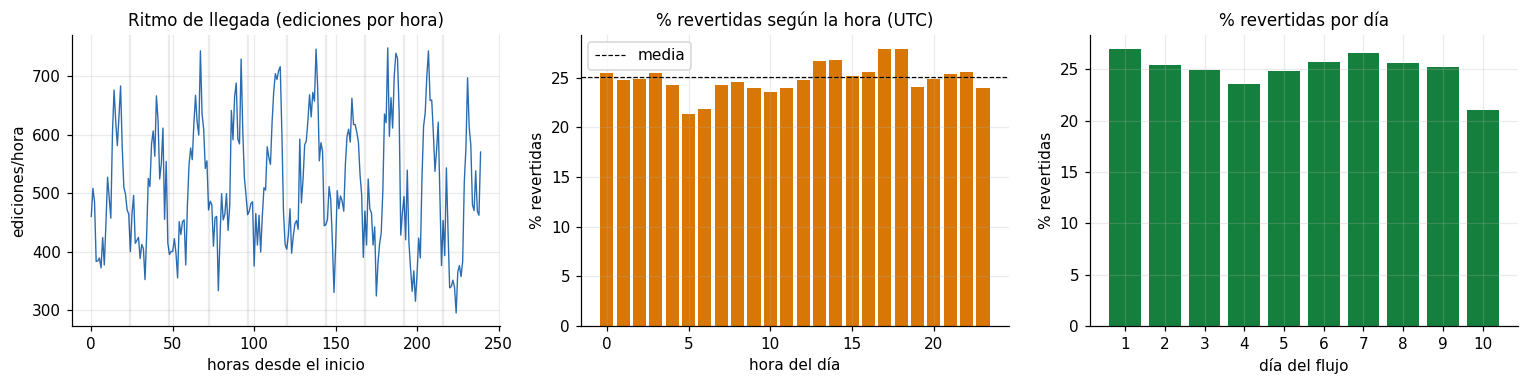

dia                1        2        3        4        5        6        7        8        9        10
ediciones     12023.0  11789.0  12281.0  12467.0  12775.0  13067.0  12331.0  12825.0  12175.0  10946.0
% revertidas     27.0     25.4     24.9     23.6     24.9     25.8     26.6     25.7     25.2     21.0

Ojo con el último día: el % de revertidas baja, pero no es que de repente haya menos vandalismo. Descargamos los datos poco después,
y a las ediciones más recientes no les había dado tiempo a que alguien las revirtiera (censura por la derecha).


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))

# (a) ritmo de llegada
por_hora = df.groupby(df["h_rel"].astype(int)).size()
ax[0].plot(por_hora.index, por_hora.values, color=COL["Texto"], lw=.9)
ax[0].set(title="Ritmo de llegada (ediciones por hora)", xlabel="horas desde el inicio", ylabel="ediciones/hora")
for d_ in range(24, int(df.h_rel.max()), 24):
    ax[0].axvline(d_, color="k", alpha=.08)

# (b) tasa de reversión por hora del día
hora_dia = df.groupby(df.timestamp.dt.hour).revertida.mean()
ax[1].bar(hora_dia.index, hora_dia.values * 100, color=COL["Numérico"])
ax[1].axhline(df.revertida.mean() * 100, color="k", ls="--", lw=.8, label="media")
ax[1].set(title="% revertidas según la hora (UTC)", xlabel="hora del día", ylabel="% revertidas"); ax[1].legend()

# (c) tasa de reversión por día
por_dia = df.groupby("dia").revertida.agg(["size", "mean"])
ax[2].bar(por_dia.index, por_dia["mean"] * 100, color=COL["Apilado"])
ax[2].set(title="% revertidas por día", xlabel="día del flujo", ylabel="% revertidas", xticks=list(por_dia.index))
plt.tight_layout(); plt.show()

print(por_dia.rename(columns={"size": "ediciones", "mean": "% revertidas"}).assign(**{"% revertidas": lambda t: (t["% revertidas"] * 100).round(1)}).T.to_string())
print("\nOjo con el último día: el % de revertidas baja, pero no es que de repente haya menos vandalismo. Descargamos los datos poco después,\ny a las ediciones más recientes no les había dado tiempo a que alguien las revirtiera (censura por la derecha).")

El ritmo de llegada tiene un ciclo diario muy marcado. Según la hora, llegan entre 300 y 750 ediciones, y el dibujo se repite casi igual todos los días. De media salen unas 500 por hora, que es la cifra de la introducción. Esto conviene tenerlo presente para la sección 5: cualquier detector que mire el flujo de cerca va a ver subidas y bajadas cada día, y eso no es un cambio, es el ritmo normal de Wikipedia.

La hora también influye en las reversiones, aunque menos de lo que se podría pensar. El porcentaje va de un 21 % a las 5–6 de la mañana (UTC) a un 28 % hacia las 17–18 h. Hay diferencia, pero no es enorme. Por eso la hora entra en el modelo como una variable más (`h_sin`, `h_cos`) y no esperamos que decida mucho por sí sola.

Por días, el porcentaje de revertidas es bastante estable: entre el 23,6 % y el 27 % los nueve primeros días. Es una primera pista de que el problema no cambia mucho en estos diez días, y en las secciones 5 y 11 lo comprobamos con más cuidado. La excepción es el día 10, que baja al 21 %, pero eso tiene otra explicación, la de la nota de arriba.

## 5. Data drift: ¿cambian los datos?

Antes de elegir modelos queremos saber si lo que llega cambia con el tiempo. Si cambiara mucho, tendríamos que buscar modelos que olviden o que se adapten solos. Si no, basta con que sigan aprendiendo.

Bajo el nombre de *model drift* se juntan dos cosas distintas, y conviene separarlas:

- **Data drift**: cambia la distribución de lo que llega, las variables de entrada. Ediciones más grandes, resúmenes distintos, otro tipo de páginas. Puede pasar sin que cambie nada importante, si la relación con la etiqueta se mantiene.
- **Concept drift**: cambia la relación entre lo que llega y la etiqueta. Lo que antes se revertía ya no se revierte, o al revés. Es el que de verdad hace daño, porque el modelo sigue aplicando lo que aprendió y deja de acertar.

El data drift se puede estudiar ya, porque solo mira las entradas: no necesita etiquetas ni modelo. El concept drift no. Los detectores de concept drift vigilan los fallos de un modelo, así que lo dejamos para la sección 11, cuando ya tengamos el ganador.

Para el data drift usamos los métodos de ventana que vimos en clase, que son los pensados para esto:

- **KSWIN** guarda una ventana de tamaño fijo y compara, con el test de Kolmogorov-Smirnov, las observaciones más recientes con una muestra de las anteriores. No mira solo la media: también ve cambios de dispersión o de forma. Su punto débil es que da falsos positivos con facilidad y depende mucho del tamaño de ventana.
- **ADWIN** usa una ventana que crece mientras todo está estable y se recorta cuando detecta un cambio en la media. No hay que fijar el tamaño. Su punto débil es que solo ve la media, y en clase se recomendaba para flujos sin estacionalidad. Wikipedia tiene un ritmo diario claro, así que habrá que leer sus alarmas con eso en mente.

Además comparamos cada día con los tres primeros, variable a variable, con el estadístico KS, que tampoco necesita etiquetas

Page-Hinkley también puede vigilar una variable de entrada, pero aquí no lo usamos. Está pensado para cambios bruscos en la media de una señal acotada, como una tasa de error. Sobre algo con colas tan largas como el cambio de tamaño, en una primera prueba daba cientos de falsas alarmas.

Un matiz de método: este análisis usa los diez días, incluidos los que luego sirven para evaluar. Como no mira la etiqueta, no le da ventaja a ningún modelo.

### 5.1 Primer vistazo: vocabulario y cambio de tamaño

Empezamos con dos comprobaciones sencillas.

La primera es contar cuántas palabras de los resúmenes de cada día no habían salido nunca antes. Si ese porcentaje no baja con los días, el modelo de texto no puede dejar de aprender en ningún momento: siempre le va a llegar vocabulario nuevo.

La segunda es pasar KSWIN sobre el cambio de tamaño de las ediciones. Esta variable es continua, tiene signo y colas largas, y puede cambiar sin que se mueva la media: basta con que haya a la vez más borrados grandes y más añadidos grandes. Un detector de medias como ADWIN no lo vería; KSWIN, que compara la distribución entera, sí. Usamos `window_size=100` y `stat_size=30`, la ventana corta de los ejemplos de clase.

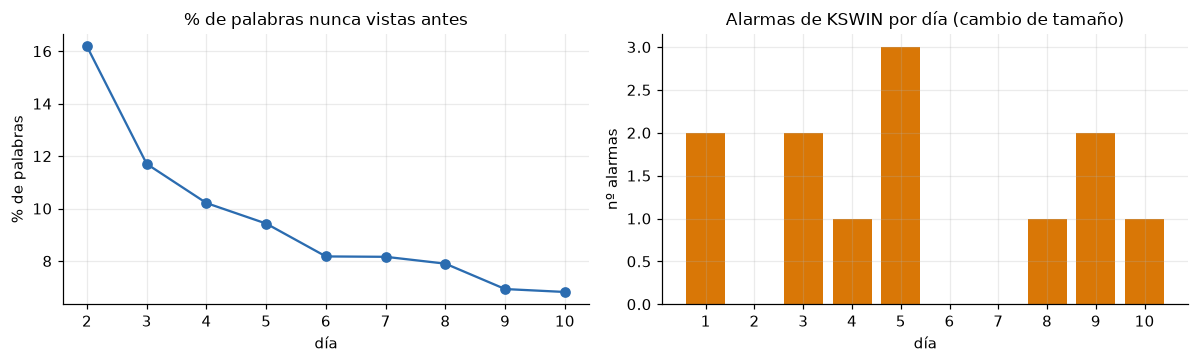

KSWIN: 12 alarmas en 122,679 ediciones


In [ ]:
# (1) % de palabras de cada día que no se habían visto en los días anteriores
vistas, nuevo = set(), {}
for d_, g in df.groupby("dia"):
    palabras = [w for c in g.comment.str.lower() for w in re.findall(r"[a-z]{3,}", c)]
    if d_ > 1 and palabras:
        nuevo[d_] = 100 * np.mean([w not in vistas for w in palabras])
    vistas.update(palabras)

# (2) KSWIN sobre el cambio de tamaño (en el orden del flujo)
kswin = drift.KSWIN(alpha=0.0001, window_size=100, stat_size=30, seed=42)      # alpha pequeño: hace un test por edición y con 0,005 daba 147 alarmas, casi todas falsas
alarmas_ks = []
for i, (v, d_) in enumerate(zip(np.sign(df.newlen - df.oldlen) * np.log1p((df.newlen - df.oldlen).abs()), df.dia)):
    kswin.update(float(v))
    if kswin.drift_detected:
        alarmas_ks.append(d_)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(list(nuevo.keys()), list(nuevo.values()), "o-", color=COL["Texto"])
ax[0].set(title="% de palabras nunca vistas antes", xlabel="día", ylabel="% de palabras", xticks=list(nuevo.keys()))
conteo = pd.Series(alarmas_ks).value_counts().reindex(range(1, df.dia.max() + 1), fill_value=0)
ax[1].bar(conteo.index, conteo.values, color=COL["Numérico"])
ax[1].set(title="Alarmas de KSWIN por día (cambio de tamaño)", xlabel="día", ylabel="nº alarmas", xticks=list(conteo.index))
plt.tight_layout(); plt.show()
print(f"KSWIN: {len(alarmas_ks)} alarmas en {len(df):,} ediciones")

El vocabulario nuevo va bajando, pero no llega a cero: el segundo día el 16 % de las palabras no se había visto nunca, y el décimo todavía es un 7 %. Así que el modelo de texto tiene que seguir aprendiendo todo el rato.

En el cambio de tamaño, KSWIN da 12 alarmas en diez días, repartidas sin ningún patrón: ningún día pasa de tres y hay días sin ninguna. No parece que haya un cambio de verdad en esta variable, más bien algún pico suelto. En 5.2 lo miramos con más calma, variable por variable.

### 5.2 Variable por variable

Ahora lo miramos con más detalle, de tres formas:

1. Un **mapa de variables por día**. Para cada variable y cada día medimos cuánto se parece su distribución a la de los tres primeros días, con el estadístico KS (0 es igual, 1 es totalmente distinta).
2. **ADWIN sobre cada variable**, en línea, contando cuántas alarmas da cada día.
3. Un **cambio inyectado** en una variable, para comprobar que ADWIN y KSWIN lo detectan si de verdad ocurre.

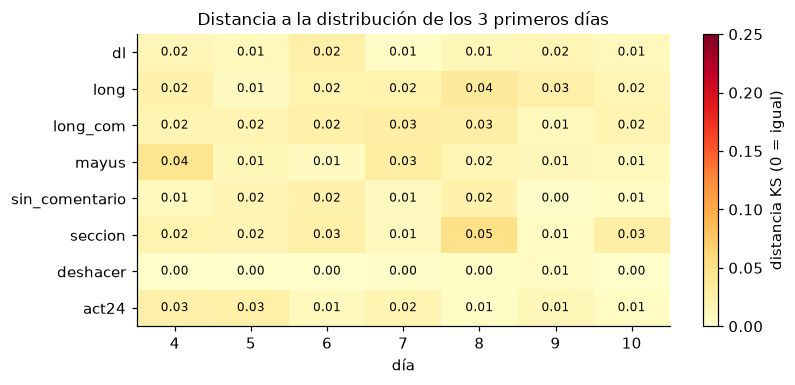

In [ ]:
# ------------------------------------------------------------------ 1) Mapa variable × día frente a los 3 primeros días
FEAT = pd.DataFrame([{k: x[k] for k in NUM} for x, y, ts in flujo(df)])                       # las mismas variables que ven los modelos (una pasada)
VARS = ["dl", "long", "long_com", "mayus", "sin_comentario", "seccion", "deshacer", "act24"]
ref = (df.dia <= DIAS_AJUSTE).values
dias_ev = list(range(DIAS_AJUSTE + 1, df.dia.max() + 1))
mapa = pd.DataFrame({d_: {v: ks_2samp(FEAT[v][ref], FEAT[v][(df.dia == d_).values]).statistic for v in VARS} for d_ in dias_ev})

fig, ax = plt.subplots(figsize=(7.5, 3.6))
im = ax.imshow(mapa.values, cmap="YlOrRd", vmin=0, vmax=max(0.25, mapa.values.max()), aspect="auto")
ax.set(xticks=range(len(dias_ev)), xticklabels=dias_ev, yticks=range(len(mapa)), yticklabels=mapa.index, xlabel="día", title="Distancia a la distribución de los 3 primeros días")
ax.grid(False)
for i in range(mapa.shape[0]):
    for j in range(mapa.shape[1]):
        ax.text(j, i, f"{mapa.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, ax=ax, label="distancia KS (0 = igual)"); plt.tight_layout(); plt.show()

Las variables no cambian. Todos los valores del mapa están en 0,05 o por debajo, y casi todos entre 0,01 y 0,03, que son diferencias muy pequeñas. Lo que llega el día 10 se parece mucho a lo que llegaba los tres primeros días.

In [ ]:
# ------------------------------------------------------------------ 2) Detectores en línea (ADWIN) sobre cada variable: alarmas por día
filas = {}
for v in VARS:
    det, dias_al = drift.ADWIN(), []
    for val, d_ in zip(FEAT[v].values, df.dia.values):
        det.update(float(val))
        if det.drift_detected:
            dias_al.append(d_)
    filas[v] = pd.Series(dias_al, dtype=int).value_counts().reindex(range(1, df.dia.max() + 1), fill_value=0)
tic("detectores sobre variables")
print("Si las alarmas se repiten todos los días en las mismas horas, es el ritmo diario de la Wikipedia y no un cambio real.")
pd.DataFrame(filas).T

[ 49.5 min] detectores sobre variables
Si las alarmas se repiten todos los días en las mismas horas, es el ritmo diario de la Wikipedia y no un cambio real.


,1,2,3,4,5,6,7,8,9,10
dl,0,1,0,2,2,0,1,1,0,3
long,1,2,2,3,2,2,2,1,2,2
long_com,2,2,2,2,3,2,3,4,4,2
mayus,0,0,0,2,0,0,0,0,0,0
sin_comentario,2,2,1,1,2,3,1,3,1,1
seccion,1,2,4,2,1,0,3,3,1,1
deshacer,0,0,0,2,0,1,2,2,4,0
act24,2,3,3,6,2,6,3,6,6,8


ADWIN da pocas alarmas y repartidas, entre 0 y 4 al día en casi todas las variables. Solo act24 (la actividad de la página en las últimas 24 horas) llega a 6 u 8 algunos días. Tiene una explicación sencilla, ya que esa variable sube y baja cada día con el ritmo de Wikipedia, y ADWIN lo confunde con un cambio. Un cambio real se vería de otra forma, con muchas alarmas juntas a partir de un día concreto. Y eso no pasa.

In [ ]:
# ------------------------------------------------------------------ 3) Cambio inyectado en los datos (no en la relación con la etiqueta)
def alarmas_datos(detector, serie):
    out = []
    for i, v in enumerate(serie):
        detector.update(float(v))
        if detector.drift_detected:
            out.append(i)
    return out


dl_ev = FEAT["dl"].values[df.h_rel.values >= 24 * DIAS_AJUSTE]
h_dl = df.h_rel.values[df.h_rel.values >= 24 * DIAS_AJUSTE]
mitad_d = len(dl_ev) // 2
dl_inj = dl_ev.copy(); dl_inj[mitad_d:] += 2.0                                   # desde la mitad, las ediciones cambian más de tamaño (≈ 0,5 desviaciones típicas)
DET_DATOS = {"ADWIN": lambda: drift.ADWIN(),
             "KSWIN": lambda: drift.KSWIN(alpha=0.0001, window_size=100, stat_size=30, seed=42)}      # KSWIN con alpha pequeño: hace un test por edición y con 0,005 daba muchas falsas alarmas
filas = []
for nom, mk in DET_DATOS.items():
    a = alarmas_datos(mk(), dl_inj)
    antes = [i for i in a if i < mitad_d]; despues = [i for i in a if i >= mitad_d]
    filas.append({"detector": nom, "alarmas antes del cambio": len(antes), "retraso en detectar (ediciones)": (despues[0] - mitad_d) if despues else None,
                  "retraso (horas)": round(h_dl[despues[0]] - h_dl[mitad_d], 1) if despues else None})
tic("cambio inyectado en datos")
print("Cambio inyectado en el cambio de tamaño de las ediciones (+2 en escala logarítmica, ≈ 0,5 desviaciones típicas) a partir de la mitad del periodo de evaluación.")
pd.DataFrame(filas).set_index("detector")

Cambio inyectado en el cambio de tamaño de las ediciones (+2 en escala logarítmica, ≈ 0,5 desviaciones típicas) a partir de la mitad del periodo de evaluación.


          alarmas antes del cambio  retraso en detectar (ediciones)  retraso (horas)
detector                                                                            
ADWIN                            5                               66              0.1
KSWIN                            3                             8584             15.7

Con el cambio inyectado, ADWIN lo ve casi al instante, en 66 ediciones (unos 6 minutos), mientras que KSWIN tarda casi 16 horas. Es la diferencia de la que hablábamos al principio: ADWIN está hecho para detectar cambios de media, y este es justo un cambio de media. KSWIN vigila la forma de toda la distribución, y con un alpha tan estricto tarda mucho en notar que toda la distribución se ha desplazado un poco. No es que uno sea mejor; buscan cosas distintas, y por eso usamos los dos.

**En estos diez días los datos no cambian de forma apreciable.** Los detectores funcionan, porque encuentran el cambio que metemos a propósito, pero en el flujo real no ven nada que apunte a un cambio importante. Lo único que se mueve todo el rato es el vocabulario (5.1).

Esto nos sirve para elegir los modelos de la sección 7:

- Como el vocabulario nuevo no se agota, los modelos de texto tienen que aprender en línea sin parar. Por eso usamos TF-IDF con Naive Bayes, que incorporan las palabras nuevas según van llegando.
- Como las variables numéricas son estables, en principio basta con la **actualización incremental**: el modelo sigue aprendiendo con cada etiqueta y no tira nada de lo aprendido. En clase vimos que es la estrategia que mejor encaja cuando los cambios son graduales o no los hay, y la más barata en tiempo y memoria.
- Aun así, metemos un modelo que se adapta solo, el ARF. Es un *ensemble* dinámico: cada árbol lleva su propio ADWIN y se sustituye cuando detecta un cambio. Así comprobamos si adaptarse ayuda o no.

Que los datos no cambien no quiere decir que no cambie la relación con la etiqueta. Eso lo comprobamos en la sección 11, con el modelo ganador. Diez días es poco tiempo, eso sí. Con meses de datos sería raro no encontrar algún cambio, y entonces estos detectores servirían para avisar.

## 6. Estrategia de aprendizaje y evaluación

El modelo aprende online, edición a edición. Cuando llega una, primero la **predice**. Aprender de ella lo hace más tarde cuando llega su etiqueta `RETRASO_H` horas después. Es la evaluación *prequential* (*test-then-train*) que vimos en clase, con una diferencia: allí la etiqueta llegaba enseguida y aquí no, porque en la realidad tampoco llega pronto.

Para manejar ese retraso a nuestra manera escribimos el bucle nosotros, siguiendo la idea de `EvaluacionSinProgressiveValScore`. En la sección 9 lo contrastamos con `evaluate.progressive_val_score(..., delay=...)` de River, y los resultados salen parecidos.

**¿Cómo medimos si funciona?** Con tres cosas.

La principal es el **ROC AUC**. Lo que el sistema le entrega al patrullero es un orden, no un sí o un no, y el AUC mide justo eso, lo bien ordenadas que quedan las ediciones. Un 0,5 es lo que daría ordenar al azar. Además no depende de ningún umbral ni de que solo un 25 % de las ediciones sean positivas.

Luego está la pregunta del principio, la del patrullero con poco tiempo. Suponemos que cada hora revisa solo el 10 % de ediciones con más riesgo, y miramos dos cosas: de las que revisa, cuántas eran malas (**precisión@10 %**), y de todas las malas, cuántas ha llegado a ver (**recall@10 %**). Como referencia, revisando al azar saldría una precisión de un 25 % y un recall del 10 %.

Y por último, lo que cuesta: ediciones por segundo y memoria que ocupa el modelo.

Los datos los partimos en el tiempo. Los tres primeros días sirven para ajustar los hiperparámetros, y la evaluación empieza el día 4. Así el ajuste nunca ve lo que luego se evalúa.

Para saber si un modelo aporta algo hace falta algo con qué compararlo. Usamos dos referencias que no aprenden nada: ordenar al azar y una regla sencilla que podría seguir cualquier patrullero, *mirar primero las ediciones que más cambian el tamaño de la página*.

In [ ]:
def prequential(modelo, datos, retraso_h=RETRASO_H, congelar_h=None, reiniciar_h=None, fabrica=None):
    """Test-then-train con etiqueta retrasada. Devuelve las puntuaciones (riesgo) de cada edición y el modelo entrenado.
    congelar_h  : deja de aprender de las ediciones posteriores a esa hora (para estudiar el drift)
    reiniciar_h : crea un modelo nuevo cada tantas horas (olvido total)"""
    ext = Extractor(retraso_h)
    pendientes = deque()                                       # (hora a la que llega la etiqueta, x, y, hora de la edición)
    score = np.zeros(len(datos))
    ts0 = datos.ts.iloc[0]
    proximo = reiniciar_h
    t0 = time.perf_counter()
    for i, (x, y, ts) in enumerate(flujo(datos, ext)):
        h = (ts - ts0) / 3600
        while pendientes and pendientes[0][0] <= ts:            # 1) llegan las etiquetas que ya tocan -> aprender
            _, xp, yp, hp = pendientes.popleft()
            if congelar_h is None or hp < congelar_h:
                modelo.learn_one(xp, yp)
        if reiniciar_h and h >= proximo:
            modelo, proximo = fabrica(), proximo + reiniciar_h
        score[i] = modelo.predict_proba_one(x).get(True, 0.5)   # 2) predecir con lo aprendido hasta ahora
        pendientes.append((ts + retraso_h * 3600, x, y, h))     # 3) la etiqueta llegará más tarde
    seg = time.perf_counter() - t0
    return {"score": score, "modelo": modelo, "seg": seg, "eps": len(datos) / seg, "ext": ext, "pendientes": pendientes}


def patrulla(score, y, horas, k=K_PATRULLA):
    """En cada hora el patrullero revisa el k% con más riesgo. Devuelve precisión y recall de esa revisión."""
    t = pd.DataFrame({"h": np.floor(horas).astype(int), "s": score, "y": y})
    orden = t.groupby("h")["s"].rank(ascending=False, method="first")
    tam = t.groupby("h")["s"].transform("size")
    sel = orden <= np.ceil(k * tam)
    return t.loc[sel, "y"].mean(), t.loc[sel, "y"].sum() / t["y"].sum()


def curva_ganancia(score, y, horas, fracs):
    return [patrulla(score, y, horas, f)[1] for f in fracs]


def evaluar(score, desde_h=24 * DIAS_AJUSTE):
    m = (df.h_rel.values >= desde_h)
    y = df.revertida.values[m]
    p, r = patrulla(score[m], y, df.h_rel.values[m])
    return {"AUC": roc_auc_score(y, score[m]), "precisión@10%": p, "recall@10%": r}


# ------------------------------------------------------------------ Referencias
rng = np.random.default_rng(0)
REF = {"Azar": rng.random(len(df)),
       "Regla de tamaño": (df.newlen - df.oldlen).abs().values.astype(float) + rng.random(len(df)) * 1e-6}
tabla_ref = pd.DataFrame({k: evaluar(v) for k, v in REF.items()}).T
tabla_ref

,AUC,precisión@10%,recall@10%
Azar,0.500517,0.250945,0.102316
Regla de tamaño,0.543379,0.298019,0.121509


Las referencias quedan donde cabía esperar. El azar da un AUC de 0,50 y encuentra el 10 % de las malas, que es lo que tiene que dar. La regla del tamaño mejora algo, pero poco: AUC de 0,54, una precisión del 30 % frente al 25 % y un recall del 12 %. O sea, las ediciones grandes se revierten un poco más, pero con eso solo no se llega muy lejos. Estos son los números que tienen que superar los modelos.

## 7. Modelos

Probamos siete modelos incrementales, agrupados en tres familias. Lo que más nos interesaba era poder comparar el mismo modelo con texto y sin texto, porque es la única forma limpia de saber si el texto sirve para algo.

La elección sale de la sección 5. El vocabulario no deja de crecer, así que todos los modelos aprenden en línea, edición a edición. Las variables numéricas no cambian, así que no hace falta que olviden. Y para comprobarlo incluimos el ARF, que sí se adapta por su cuenta.

| Familia | Modelo | Qué ve | Cómo |
|---|---|---|---|
| **Texto** | Texto (palabras) | resumen + título | `TFIDF` de palabras y bigramas + `MultinomialNB`, el clasificador de texto que vimos en clase. También probamos `ComplementNB`: acertaba lo mismo, pero en River su predicción recorre todo el vocabulario y se quedaba en unas 70 ediciones/s, así que lo descartamos |
| | Texto (caracteres) | resumen + título | `TFIDF` de trozos de 3 caracteres + `MultinomialNB`. La idea es que aguante faltas, símbolos y otros alfabetos (*balh*, *lol*, cirílico) |
| **Numérico** | Numérico (logística) | variables numéricas | `StandardScaler` + `LogisticRegression`, el modelo lineal de clase |
| | ARF numérico | variables numéricas | *Adaptive Random Forest*: un **ensemble** de árboles de Hoeffding. Cada árbol lleva su propio ADWIN y, si detecta un cambio, se sustituye por otro |
| **Ensembles apilados** | Apilado lineal | puntuaciones de texto y numérico | *Stacking*: una logística combina lo que dicen el modelo de texto y el numérico |
| | Apilado ARF | variables numéricas + puntuación del texto | El ARF recibe también la opinión del modelo de texto, y puede mezclarla con los números de forma no lineal |
| | Apilado ARF 2 textos | numéricas + texto (palabras) + texto (caracteres) | Lo mismo, pero con los dos modelos de texto |

Las variables numéricas son las de la sección 3. Hay una que conviene destacar: el **historial de reversiones de la página** (`pag_n`, `pag_rev`). Las páginas que reciben vandalismo suelen recibirlo más de una vez, así que saber qué ha pasado antes en esa página debería ayudar. Para no hacer trampa, solo cuenta las etiquetas que ya habrían llegado, con el mismo retraso que el modelo.

Los apilados los programamos a mano, siguiendo la idea del `StackingClassifier` de clase. El segundo nivel nunca ve el texto en bruto, solo las puntuaciones que dan los modelos de texto.

Los hiperparámetros los ajustamos con los tres primeros días: el suavizado de los dos modelos de texto, el optimizador de la logística (SGD, que es el que vimos en clase, frente a AdaGrad y Adam, que adaptan el paso solos) y el del meta-modelo del apilado lineal. Medimos entre los días 2 y 3, y a partir del día 4 ya no se toca nada. El ARF lo dejamos con los valores por defecto y `N_ARBOLES` árboles; ajustarlo habría alargado mucho el cuaderno.

In [ ]:
def logit(p):
    p = min(max(p, 1e-4), 1 - 1e-4)
    return math.log(p / (1 - p))


def modelo_texto(alpha=0.3, ngram=(1, 2)):
    return fx.TFIDF(on="texto", lowercase=True, ngram_range=ngram, normalize=True) | naive_bayes.MultinomialNB(alpha=alpha)


def trozos3(s):
    """Trozos de 3 caracteres consecutivos (n-gramas de caracteres)."""
    s = s.lower()
    return [s[i:i + 3] for i in range(len(s) - 2)]


def modelo_caracteres(alpha=1.0):
    return fx.TFIDF(on="texto", tokenizer=trozos3, normalize=True) | naive_bayes.MultinomialNB(alpha=alpha)


OPTIMIZADORES = {"SGD": optim.SGD, "AdaGrad": optim.AdaGrad, "Adam": optim.Adam}     # visto en clase: SGD; los adaptativos estabilizan el aprendizaje


def modelo_numerico(opt=("Adam", 0.01), claves=None):
    return compose.Select(*(claves or NUM)) | preprocessing.StandardScaler() | linear_model.LogisticRegression(optimizer=OPTIMIZADORES[opt[0]](opt[1]))


class Apilado(base.Classifier):
    """Stacking lineal: el meta-modelo recibe las puntuaciones (logit) de los modelos de texto y numérico.
    Al aprender, usa lo que los modelos base predecían ANTES de actualizarse (como StackingClassifier de River)."""

    def __init__(self, texto, numerico, opt_meta=("Adam", 0.01)):
        self.texto, self.numerico, self.opt_meta = texto, numerico, opt_meta
        self.meta = preprocessing.StandardScaler() | linear_model.LogisticRegression(optimizer=OPTIMIZADORES[opt_meta[0]](opt_meta[1]))

    def _z(self, x):
        return {"logit_texto": logit(self.texto.predict_proba_one(x).get(True, 0.5)),
                "logit_num": logit(self.numerico.predict_proba_one(x).get(True, 0.5))}

    def predict_proba_one(self, x):
        return self.meta.predict_proba_one(self._z(x))

    def learn_one(self, x, y):
        self.meta.learn_one(self._z(x), y)
        self.texto.learn_one(x, y)
        self.numerico.learn_one(x, y)
        return self


class ARFconTexto(base.Classifier):
    """Bosque adaptativo (ARF) sobre las variables numéricas y, si se le dan, las puntuaciones (logit) de uno o varios modelos de texto.
    Sin modelos de texto es el «ARF numérico»; con ellos, un apilado con árboles como segundo nivel."""

    def __init__(self, textos, n_arboles=N_ARBOLES):
        self.textos = textos                                  # dict nombre -> modelo de texto
        self.arf = forest.ARFClassifier(n_models=n_arboles, seed=1)

    def _z(self, x):
        z = {k: x[k] for k in NUM}
        for nombre, m in self.textos.items():
            z["logit_" + nombre] = logit(m.predict_proba_one(x).get(True, 0.5))
        return z

    def predict_proba_one(self, x):
        return self.arf.predict_proba_one(self._z(x))

    def learn_one(self, x, y):
        self.arf.learn_one(self._z(x), y)                     # primero el ARF (con lo que predecían los de texto antes de aprender)
        for m in self.textos.values():
            m.learn_one(x, y)
        return self


def ajustar(fabrica):
    """Prequential sobre los DIAS_AJUSTE primeros días; AUC entre el día 2 y el final del ajuste."""
    sub = df[df.h_rel < 24 * DIAS_AJUSTE].reset_index(drop=True)
    r = prequential(fabrica(), sub)
    m = sub.h_rel.values >= 24
    return roc_auc_score(sub.revertida.values[m], r["score"][m])

In [ ]:
# ------------------------------------------------------------------ Ajuste con los primeros días
def mejor_de(filas, modelo):
    return max((f for f in filas if f["modelo"] == modelo), key=lambda f: f["AUC ajuste"])["_cfg"]


filas = []
for a in [0.3, 1.0, 3.0]:
    filas.append({"modelo": "Texto (palabras)", "configuración": f"alpha={a}", "AUC ajuste": ajustar(lambda: modelo_texto(a)), "_cfg": dict(alpha=a)})
for a in [0.3, 1.0, 3.0]:
    filas.append({"modelo": "Texto (caracteres)", "configuración": f"alpha={a}", "AUC ajuste": ajustar(lambda: modelo_caracteres(a)), "_cfg": dict(alpha=a)})
for opt in [("SGD", 0.01), ("AdaGrad", 0.3), ("Adam", 0.01), ("Adam", 0.001)]:
    filas.append({"modelo": "Numérico (logística)", "configuración": f"{opt[0]}({opt[1]})", "AUC ajuste": ajustar(lambda: modelo_numerico(opt)), "_cfg": dict(opt=opt)})
MEJOR_TEXTO, MEJOR_CAR, MEJOR_NUM = (mejor_de(filas, "Texto (palabras)"), mejor_de(filas, "Texto (caracteres)"), mejor_de(filas, "Numérico (logística)"))

for opt_m in [("SGD", 0.01), ("Adam", 0.001), ("Adam", 0.01)]:
    filas.append({"modelo": "Apilado lineal", "configuración": f"meta-modelo {opt_m[0]}({opt_m[1]})",
                  "AUC ajuste": ajustar(lambda: Apilado(modelo_texto(**MEJOR_TEXTO), modelo_numerico(**MEJOR_NUM), opt_m)), "_cfg": opt_m})
OPT_META = mejor_de(filas, "Apilado lineal")
tic("ajuste terminado")
print("Elegido -> texto:", MEJOR_TEXTO, "| caracteres:", MEJOR_CAR, "| numérico:", MEJOR_NUM, "| meta-modelo:", OPT_META)
print("Si lo elegido está en un extremo de la cuadrícula, convendría probar valores más allá (limitación de este ajuste).")
pd.DataFrame(filas).drop(columns="_cfg").round(4)

[  5.7 min] ajuste terminado
Elegido -> texto: {'alpha': 1.0} | caracteres: {'alpha': 0.3} | numérico: {'opt': ('Adam', 0.001)} | meta-modelo: ('Adam', 0.001)
Si lo elegido está en un extremo de la cuadrícula, convendría probar valores más allá (limitación de este ajuste).


,modelo,configuración,AUC ajuste
0,Texto (palabras),alpha=0.3,0.6279
1,Texto (palabras),alpha=1.0,0.6352
2,Texto (palabras),alpha=3.0,0.6286
3,Texto (caracteres),alpha=0.3,0.6316
4,Texto (caracteres),alpha=1.0,0.6235
5,Texto (caracteres),alpha=3.0,0.6096
6,Numérico (logística),SGD(0.01),0.5784
7,Numérico (logística),AdaGrad(0.3),0.5693
8,Numérico (logística),Adam(0.01),0.5869
9,Numérico (logística),Adam(0.001),0.6309


En el ajuste las diferencias son pequeñas, salvo en la logística: con Adam y un paso de 0,001 llega a 0,631, y con SGD se queda en 0,578. Ahí el optimizador sí importa. En los modelos de texto, cambiar el suavizado mueve el AUC menos de dos centésimas.

Hay una pega. Dos de las opciones elegidas están en el borde de lo que probamos: `alpha=0.3` en el texto de caracteres y `Adam(0.001)`, el paso más pequeño, en la logística. Puede que más allá hubiera algo mejor. No lo hemos comprobado.

In [ ]:
# ------------------------------------------------------------------ Ejecución final: todo el flujo, evaluación desde el día 4
FABRICAS = {
    "Texto (palabras)":     lambda: modelo_texto(**MEJOR_TEXTO),
    "Texto (caracteres)":   lambda: modelo_caracteres(**MEJOR_CAR),
    "Numérico (logística)": lambda: modelo_numerico(**MEJOR_NUM),
    "ARF numérico":         lambda: ARFconTexto({}),
    "Apilado lineal":       lambda: Apilado(modelo_texto(**MEJOR_TEXTO), modelo_numerico(**MEJOR_NUM), OPT_META),
    "Apilado ARF":          lambda: ARFconTexto({"pal": modelo_texto(**MEJOR_TEXTO)}),
    "Apilado ARF 2 textos": lambda: ARFconTexto({"pal": modelo_texto(**MEJOR_TEXTO), "car": modelo_caracteres(**MEJOR_CAR)}),
}
RES = {}
for nombre, fab in FABRICAS.items():
    RES[nombre] = prequential(fab(), df)
    RES[nombre]["tam_mb"] = len(pickle.dumps(RES[nombre]["modelo"])) / 1e6
    tic(f"{nombre}: {RES[nombre]['eps']:,.0f} ediciones/s")

resumen = pd.DataFrame({n: evaluar(r["score"]) for n, r in RES.items()}).T
resumen = pd.concat([tabla_ref, resumen])
resumen.round(3)

[  6.8 min] Texto (palabras): 1,926 ediciones/s
[  8.3 min] Texto (caracteres): 1,392 ediciones/s
[  8.5 min] Numérico (logística): 10,725 ediciones/s
[ 13.4 min] ARF numérico: 415 ediciones/s
[ 15.6 min] Apilado lineal: 971 ediciones/s
[ 22.9 min] Apilado ARF: 284 ediciones/s
[ 33.0 min] Apilado ARF 2 textos: 204 ediciones/s


,AUC,precisión@10%,recall@10%
Azar,0.501,0.251,0.102
Regla de tamaño,0.543,0.298,0.122
Texto (palabras),0.655,0.444,0.181
Texto (caracteres),0.648,0.409,0.167
Numérico (logística),0.665,0.542,0.221
ARF numérico,0.636,0.457,0.186
Apilado lineal,0.682,0.526,0.214
Apilado ARF,0.658,0.468,0.191
Apilado ARF 2 textos,0.662,0.471,0.192


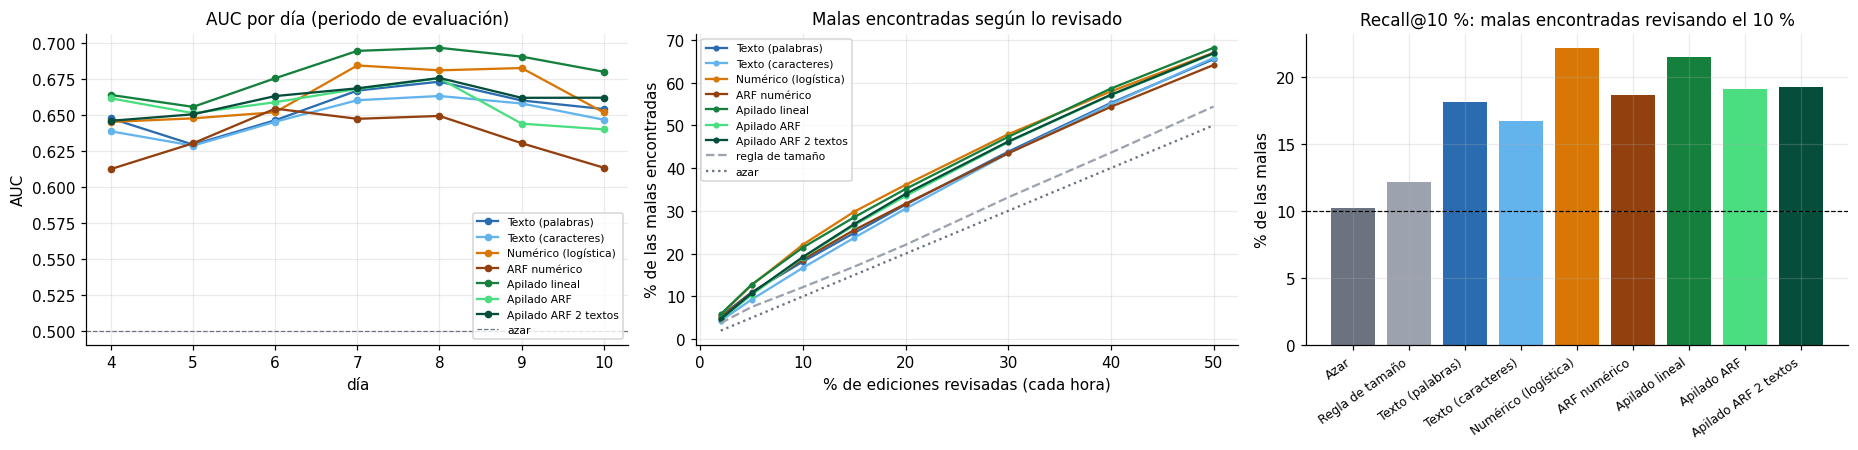

In [ ]:
desde = 24 * DIAS_AJUSTE
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))

# (a) AUC por día
dias_ev = list(range(DIAS_AJUSTE + 1, df.dia.max() + 1))
for n, r in RES.items():
    aucs = [roc_auc_score(df.revertida[df.dia == d_], r["score"][df.dia == d_]) for d_ in dias_ev]
    ax[0].plot(dias_ev, aucs, "o-", color=COL[n], label=n, ms=4)
ax[0].axhline(0.5, color=COL["Azar"], ls="--", lw=.8, label="azar")
ax[0].set(title="AUC por día (periodo de evaluación)", xlabel="día", ylabel="AUC", xticks=dias_ev); ax[0].legend(loc="lower right", fontsize=7)

# (b) % de las malas encontradas según % revisado
fracs = np.array([.02, .05, .10, .15, .20, .30, .40, .50])
m = df.h_rel.values >= desde
for n, r in RES.items():
    ax[1].plot(fracs * 100, np.array(curva_ganancia(r["score"][m], df.revertida.values[m], df.h_rel.values[m], fracs)) * 100, "o-", color=COL[n], label=n, ms=3)
reglas = REF["Regla de tamaño"]
ax[1].plot(fracs * 100, np.array(curva_ganancia(reglas[m], df.revertida.values[m], df.h_rel.values[m], fracs)) * 100, "--", color=COL["Regla"], label="regla de tamaño")
ax[1].plot(fracs * 100, fracs * 100, ":", color=COL["Azar"], label="azar")
ax[1].set(title="Malas encontradas según lo revisado", xlabel="% de ediciones revisadas (cada hora)", ylabel="% de las malas encontradas"); ax[1].legend(loc="upper left", fontsize=7)

# (c) recall@10 %
ax[2].bar(resumen.index, resumen["recall@10%"] * 100, color=[COL.get(i, COL["Regla"]) for i in resumen.index])
ax[2].axhline(10, color="k", ls="--", lw=.8)
ax[2].set(title="Recall@10 %: malas encontradas revisando el 10 %", ylabel="% de las malas")
plt.setp(ax[2].get_xticklabels(), rotation=35, ha="right", fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:
def _auc(n):
    return resumen.loc[n, "AUC"]


mejor = resumen.loc[list(RES)].AUC.idxmax()
print(f"Mejor modelo: {mejor} (AUC {_auc(mejor):.3f}, recall@10% {resumen.loc[mejor, 'recall@10%']:.1%}).")
print(f"El texto, comparando el mismo modelo con y sin él: logística {_auc('Apilado lineal') - _auc('Numérico (logística)'):+.3f} · "
      f"ARF {_auc('Apilado ARF') - _auc('ARF numérico'):+.3f} de AUC.")
print(f"Texto solo: palabras {_auc('Texto (palabras)'):.3f} · caracteres {_auc('Texto (caracteres)'):.3f}. "
      f"Añadir el texto de caracteres al apilado ARF: {_auc('Apilado ARF 2 textos') - _auc('Apilado ARF'):+.3f}.")
print(f"Árboles (ARF) frente a logística, solo con variables numéricas: {_auc('ARF numérico') - _auc('Numérico (logística)'):+.3f} de AUC.")
GANADOR = mejor

Mejor modelo: Apilado lineal (AUC 0.682, recall@10% 21.4%).
El texto, comparando el mismo modelo con y sin él: logística +0.016 · ARF +0.022 de AUC.
Texto solo: palabras 0.655 · caracteres 0.648. Añadir el texto de caracteres al apilado ARF: +0.004.
Árboles (ARF) frente a logística, solo con variables numéricas: -0.030 de AUC.


**¿Qué sacamos de aquí?**

Lo primero es que todos los modelos aprenden algo. El peor tiene un AUC de 0,636, frente al 0,543 de la regla del tamaño. Y la mejora se nota donde importa: revisando el 10 % de las ediciones, los mejores modelos encuentran entre el 21 % y el 22 % de las malas, el doble que el azar. Además, más de la mitad de lo que revisa el patrullero acaba siendo revertido (54 % con la logística), cuando de media es el 25 %.

Por AUC gana el **apilado lineal** (0,682). Pero si miramos lo que de verdad le importa al patrullero, el 10 % de arriba, la **logística numérica sola** queda un poco por delante: recall del 22,1 % frente al 21,4 % y precisión del 54 % frente al 53 %. La ventaja del texto se reparte por toda la lista, no en la parte de arriba, que es la que se revisa. En la curva del centro se ve que todos los modelos van casi pegados.

Sobre el texto: ayuda, pero menos de lo que esperábamos. Solo, se queda por debajo de las variables numéricas (0,655 frente a 0,665). Añadido a un modelo, suma entre 0,016 y 0,022 de AUC. Los trozos de caracteres tampoco mejoran a las palabras, y meter los dos en el apilado ARF apenas añade 0,004.

Los árboles salen peor que la logística: el ARF numérico pierde 0,030 de AUC frente a ella. En la gráfica por días se ve algo más. El día 9, los dos modelos lineales se mantienen, pero los de árboles ya bajan: el ARF numérico pasa de 0,65 a 0,63 y el apilado ARF, de 0,675 a 0,645. El día 10 el ARF numérico se queda en 0,61, el más bajo de todos. Es verdad que el ARF no está ajustado, así que no lo damos como algo definitivo.

En coste no hay problema con ninguno. El más lento, el apilado ARF con dos textos, procesa unas 200 ediciones por segundo, y llegan unas 500 por *hora*. La logística va a más de 10.000 por segundo. Elegir entre ellos es cuestión de calidad, no de velocidad.

Un detalle de la gráfica por días: casi todos bajan el día 10. Probablemente no es que el modelo empeore. Es el mismo efecto de la sección 4: a esas ediciones aún no les había dado tiempo a ser revertidas cuando bajamos los datos, y el AUC se calcula con etiquetas incompletas.

In [ ]:
# ------------------------------------------------------------------ Ablación: ¿cuánto aporta el historial de la página?
NUM_SIN_PAG = [k for k in NUM if not k.startswith("pag_n") and k != "pag_rev"]
r_sin = prequential(modelo_numerico(**MEJOR_NUM, claves=NUM_SIN_PAG), df)
print(f"Numérico (logística) sin historial de la página: AUC {evaluar(r_sin['score'])['AUC']:.3f} · con historial: {_auc('Numérico (logística)'):.3f}")
for n in ("ARF numérico", "Apilado ARF"):                      # cuántos cambios detectaron los ADWIN internos de los árboles
    try:
        print(f"{n}: {RES[n]['modelo'].arf.n_drifts_detected()} cambios detectados por los ADWIN internos del ARF")
    except Exception:
        pass

Numérico (logística) sin historial de la página: AUC 0.613 · con historial: 0.665
ARF numérico: 63 cambios detectados por los ADWIN internos del ARF
Apilado ARF: 53 cambios detectados por los ADWIN internos del ARF


Quitar el historial de la página le cuesta a la logística 0,052 de AUC (de 0,665 a 0,613). Es lo que más aporta de todo lo que hemos probado, más que el texto. Tiene sentido: si una página ya ha sufrido vandalismo, lo más probable es que lo vuelva a sufrir.

Los ADWIN internos del ARF detectan 63 cambios en el ARF numérico y 53 en el apilado ARF, y cada uno supone reemplazar un árbol. Son bastantes para diez días. Puede que tenga que ver con que el ARF vaya peor que la logística, que no olvida nada, pero esto solo es una sospecha. En la sección 11 miramos el concept drift directamente.

## 8. El retraso de la etiqueta

Que una edición es mala solo lo sabemos cuando alguien la revierte. Eso puede tardar minutos, horas o días, y mientras tanto el modelo no puede aprender de ella.

El problema es que no sabemos cuánto tarda de verdad. En los datos que bajamos aparece si una edición se revirtió, pero no cuándo. Así que el retraso de 6 horas que usamos en todo el cuaderno es una suposición. En vez de darlo por bueno, repetimos el experimento con el mejor modelo (el apilado lineal) y retrasos de 0, 1, 6 y 24 horas, para ver cuánto cambia.

El caso de 0 horas no es realista: supone que la etiqueta llega en el mismo instante que la edición. Lo incluimos como techo, para saber cuánto se pierde por tener que esperar. Lo que nos importa es lo que pasa entre 1 y 24 horas.

[ 35.3 min] retraso 0 h
[ 37.3 min] retraso 1 h
[ 37.3 min] retraso 6 h
[ 39.3 min] retraso 24 h


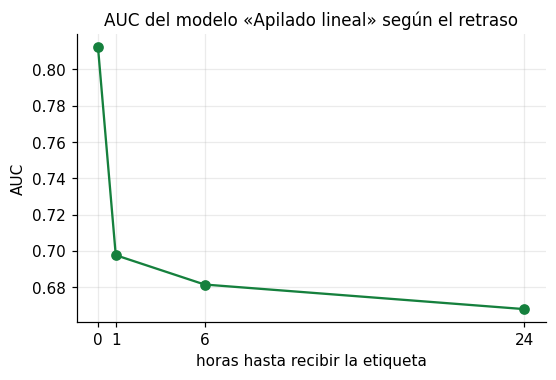

,AUC,precisión@10%,recall@10%
retraso (h),,,
0,0.812,0.754,0.307
1,0.698,0.552,0.225
6,0.682,0.526,0.214
24,0.668,0.491,0.200


In [ ]:
filas = []
for h_ret in [0, 1, 6, 24]:
    r = RES[GANADOR] if h_ret == RETRASO_H else prequential(FABRICAS[GANADOR](), df, retraso_h=h_ret)
    filas.append({"retraso (h)": h_ret, **evaluar(r["score"])})
    tic(f"retraso {h_ret} h")
sens = pd.DataFrame(filas).set_index("retraso (h)")
fig, ax = plt.subplots(figsize=(5.5, 3.4))
ax.plot(sens.index, sens["AUC"], "o-", color=COL["Apilado"])
ax.set(title=f"AUC del modelo «{GANADOR}» según el retraso", xlabel="horas hasta recibir la etiqueta", ylabel="AUC", xticks=list(sens.index)); plt.show()
sens.round(3)

Entre 1 y 24 horas el modelo pierde algo, pero no mucho. El AUC baja de 0,698 a 0,668 y el recall@10 % pasa del 22,5 % al 20 %. Con 24 horas de espera seguimos encontrando el doble de malas que el azar, así que la suposición de las 6 horas no cambia las conclusiones de la sección 7: si el retraso real fuera mayor o menor, los números se moverían unas centésimas.

El salto está en las 0 horas, que dan un AUC de 0,812. Es mucho más de lo que se gana pasando de 24 h a 1 h, y creemos que se debe sobre todo al historial de la página. Con retraso cero, en cuanto se revierte una edición el modelo ya lo sabe, y el vandalismo suele llegar en rachas: la misma persona edita varias veces la misma página en pocos minutos. Si la edición anterior era mala, la siguiente probablemente también. Con una hora de espera, muchas veces la racha ya ha terminado cuando llega la etiqueta. No lo hemos comprobado aparte, pero es la explicación que más encaja.

Esto deja una idea práctica: cuanto antes le llegue la etiqueta al modelo, mejor. En un sistema real no habría que esperar horas; se podrían escuchar las reversiones según ocurren y pasárselas al modelo en ese momento. No llegaríamos al 0,81, porque alguien tiene que revertir primero, pero sí a algo por encima de lo que vemos con 6 horas.

## 9. Eficiencia: tiempo y memoria

Un modelo de flujos tiene dos obligaciones que en un problema por lotes no existen. Tiene que ir más rápido de lo que llegan los datos, porque si no se le acumulan. Y no puede ir ocupando cada vez más memoria, porque el flujo no se acaba nunca.

Así que medimos dos cosas: cuántas ediciones procesa cada modelo por segundo y cuánto ocupa una vez entrenado con todo el flujo.

Aprovechamos también para comparar nuestro bucle con la función de River, `progressive_val_score`, usando `delay` para el retraso y `show_time` y `show_memory` para el coste. Esto último lo hacemos solo con las primeras 20.000 ediciones.

In [ ]:
llegada = len(df) / (df.ts.iloc[-1] - df.ts.iloc[0])
efi = pd.DataFrame({n: {"ediciones/s": r["eps"], "tamaño del modelo (MB)": r["tam_mb"]} for n, r in RES.items()}).T
print(f"Ritmo real de llegada: {llegada:.2f} ediciones/s. Cada modelo procesa entre {efi['ediciones/s'].min():,.0f} y {efi['ediciones/s'].max():,.0f} por segundo.")
efi.round(3)

Ritmo real de llegada: 0.14 ediciones/s. Cada modelo procesa entre 204 y 10,725 por segundo.


,ediciones/s,tamaño del modelo (MB)
Texto (palabras),1925.606,19.984
Texto (caracteres),1392.288,1.509
Numérico (logística),10724.929,0.002
ARF numérico,414.637,12.139
Apilado lineal,970.578,19.987
Apilado ARF,284.492,48.896
Apilado ARF 2 textos,204.498,45.933


La velocidad no es ningún problema. Llegan 0,14 ediciones por segundo y el modelo más lento procesa unas 200, así que va unas 1.400 veces más rápido de lo necesario. La logística, que es la más rápida, va unas 75.000 veces más rápido.

Con la memoria la cosa cambia bastante de un modelo a otro. La logística ocupa 2 KB, porque solo guarda un peso por variable, y eso no cambia por muchas ediciones que pasen. Los modelos de texto son otra historia: el de palabras ocupa 20 MB, porque guarda cada palabra y cada pareja de palabras que ha visto. Y en la sección 5 vimos que cada día aparece un 7 % de vocabulario nuevo, así que **esa memoria no deja de crecer**. Para diez días no es un problema, pero en un sistema que funcione meses habría que podar el vocabulario de vez en cuando.

El modelo de caracteres sale mucho mejor parado: 1,5 MB, trece veces menos que el de palabras, con un AUC casi igual (0,648 frente a 0,655). Tiene sentido, porque los trozos de 3 letras posibles son muchos menos que las palabras posibles y se acaban repitiendo.

Los modelos con ARF ocupan entre 12 y 49 MB. Los árboles crecen, pero el propio ARF los va reemplazando cuando detecta un cambio, y eso pone un cierto límite.

In [ ]:
# ------------------------------------------------------------------ Contraste con la función oficial de River (muestra del flujo: las primeras 20.000 ediciones)
muestra = df.head(20000).reset_index(drop=True)
for n, fab in FABRICAS.items():
    print(f"--- {n}")
    evaluate.progressive_val_score(como_river(muestra), fab(), metrics.ROCAUC(), moment="ts_dt",
                                   delay=dt.timedelta(hours=RETRASO_H), print_every=10000, show_time=True, show_memory=True)

# Nuestro bucle, mismas 20.000 ediciones y mismo AUC acumulado desde la primera edición. Son más bajos que en la tabla de la sección 7
# porque incluyen el calentamiento (los primeros días el modelo aún casi no ha aprendido); allí se mide desde el día 4.
print("\nNuestro bucle en esas mismas 20.000 ediciones (AUC acumulado, incluye el calentamiento):")
for n in FABRICAS:
    print(f"  {n}: {roc_auc_score(df.revertida.values[:20000], RES[n]['score'][:20000]):.4f}")

--- Texto (palabras)
[10,000] ROCAUC: 57.42% – 00:00:06 – 25.26 MiB
[20,000] ROCAUC: 59.90% – 00:00:11 – 42 MiB
--- Texto (caracteres)
[10,000] ROCAUC: 58.42% – 00:00:08 – 4.69 MiB
[20,000] ROCAUC: 59.91% – 00:00:15 – 5.88 MiB
--- Numérico (logística)
[10,000] ROCAUC: 51.59% – 00:00:01 – 6.84 KiB
[20,000] ROCAUC: 55.27% – 00:00:03 – 6.84 KiB
--- ARF numérico
[10,000] ROCAUC: 53.74% – 00:00:21 – 42.44 MiB
[20,000] ROCAUC: 56.05% – 00:00:44 – 45.86 MiB
--- Apilado lineal
[10,000] ROCAUC: 53.45% – 00:00:11 – 25.27 MiB
[20,000] ROCAUC: 58.30% – 00:00:22 – 42.01 MiB
--- Apilado ARF
[10,000] ROCAUC: 57.14% – 00:00:28 – 66.65 MiB
[20,000] ROCAUC: 59.31% – 00:01:00 – 71.33 MiB
--- Apilado ARF 2 textos
[10,000] ROCAUC: 56.84% – 00:00:41 – 75.04 MiB
[20,000] ROCAUC: 59.77% – 00:01:30 – 104.76 MiB

Nuestro bucle en esas mismas 20.000 ediciones (AUC acumulado, incluye el calentamiento):
  Texto (palabras): 0.5820
  Texto (caracteres): 0.5838
  Numérico (logística): 0.5552
  ARF numérico: 0.5488
  

Los AUC no coinciden exactamente con los nuestros. Por ejemplo, el texto de palabras da 0,599 con River y 0,582 con nuestro bucle. La razón principal es que el `ROCAUC` de River es una aproximación: para no guardar todas las predicciones, calcula la curva con solo 10 umbrales. Aun así, las dos formas cuentan lo mismo: los modelos que usan texto quedan por delante de los que solo usan números.

En la memoria, lo que importa es la tendencia. Entre las 10.000 y las 20.000 ediciones, la logística se queda en 6,84 KiB, mientras que el modelo de palabras pasa de 25 a 42 MiB. Es lo mismo que decíamos arriba: el texto crece y la logística no. Las cifras de River son más altas que las de la tabla porque mide el objeto en memoria con todo lo que lleva alrededor, y nosotros medimos lo que ocupa guardado en disco.

In [ ]:
# ------------------------------------------------------------------ ¿Cuánto cuesta el texto? Unigramas frente a unigramas+bigramas
filas = []
for ng in [(1, 1), (1, 2)]:
    r = prequential(modelo_texto(MEJOR_TEXTO["alpha"], ng), df)
    filas.append({"n-gramas": str(ng), **evaluar(r["score"]), "tamaño (MB)": len(pickle.dumps(r["modelo"])) / 1e6, "ediciones/s": r["eps"]})
pd.DataFrame(filas).set_index("n-gramas").round(3)

,AUC,precisión@10%,recall@10%,tamaño (MB),ediciones/s
n-gramas,,,,,
"(1, 1)",0.642,0.415,0.169,3.299,2520.469
"(1, 2)",0.655,0.444,0.181,19.984,1884.414


Los bigramas sí compensan, pero salen caros. Pasar de solo palabras a palabras más parejas de palabras sube el AUC de 0,642 a 0,655 y el recall@10 % del 16,9 % al 18,1 %. A cambio, el modelo ocupa seis veces más (de 3,3 a 20 MB) y va un 25 % más lento.

Nos quedamos con los bigramas porque la velocidad sobra y 20 MB no es nada. Pero si este sistema tuviera que funcionar mucho tiempo, sería lo primero que revisaríamos, por lo que ya dijimos del vocabulario que no para de crecer.

## 10. Agrupamiento: ¿qué tipos de ediciones hay?

Hasta ahora siempre hemos mirado la etiqueta. Aquí no: agrupamos las ediciones sin saber si se revirtieron o no, también en flujo, y solo después miramos qué ha salido.

Para agrupar usamos únicamente cómo es la edición: cuánto cambia el tamaño, cuánto medía la página, si tiene resumen, si es de una sección, cuántas mayúsculas lleva y si dice que deshace algo. Dejamos fuera la hora y el historial de la página, porque queremos tipos de edición, no tipos de página ni de momento del día.

Probamos dos algoritmos. **KMeans**, con 8 grupos, y **DBSTREAM**, que agrupa por densidad y no necesita que le digamos cuántos grupos hay. Con los grupos hechos, la pregunta es sencilla: ¿hay algún tipo de edición que se revierta mucho más que el resto? Al final de la sección miramos además si el reparto de tipos cambia con los días, que es otra forma de buscar data drift.

Intentamos también usar `TextClust`, el agrupamiento de texto de River, pero no funcionó bien. Los resúmenes son tan cortos y tan distintos entre sí que creaba cientos de grupos minúsculos, casi vacíos, y además iba a unas 300 ediciones por segundo. Lo dejamos.

[ 46.2 min] agrupamiento


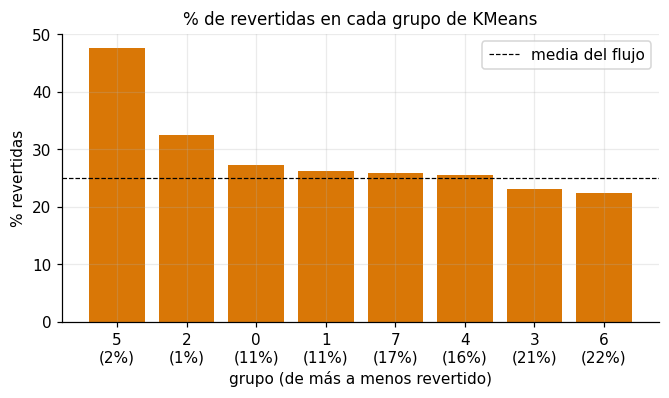

DBSTREAM: 13 grupos con ≥ 1 % de las ediciones; % revertidas entre 20% y 30% (KMeans: entre 22% y 48%; media del flujo 25%).
Los grupos describen tipos de edición; no se usan como variable porque lo que ven ya lo ven los modelos numéricos.


,ediciones,revertidas,sin_resumen,seccion,deshacer,tam_mediano,% del total
g,,,,,,,
5,1892,47.7,0.0,3.0,100.0,78.0,1.5
2,721,32.5,0.0,29.7,0.1,34.0,0.6
0,13561,27.2,99.9,0.0,0.0,20.0,11.1
1,13636,26.2,99.9,0.0,0.0,23.0,11.1
7,20470,25.9,0.0,37.0,0.0,28.0,16.7
4,19612,25.6,0.0,70.4,0.0,24.0,16.0
3,25874,23.1,0.0,94.7,0.0,23.0,21.1
6,26913,22.4,0.0,90.5,0.0,23.0,21.9


In [ ]:
# ------------------------------------------------------------------ Agrupamiento en línea (FEAT, las variables de todo el flujo, se calculó en la sección 5)
CARAC = ["dl", "long", "sin_comentario", "seccion", "long_com", "mayus", "deshacer"]          # solo cómo es la edición (sin hora ni historial)


def agrupar(modelo):
    """Test-then-train: cada edición se asigna a un grupo con lo aprendido hasta entonces y luego el modelo aprende de ella."""
    esc, g = preprocessing.StandardScaler(), []
    for z in FEAT[CARAC].to_dict("records"):
        esc.learn_one(z); z = esc.transform_one(z)
        g.append(modelo.predict_one(z)); modelo.learn_one(z)
    return np.array(g)


g_km = agrupar(cluster.KMeans(n_clusters=8, halflife=0.1, sigma=1, seed=1))
g_db = agrupar(cluster.DBSTREAM(clustering_threshold=0.8, fading_factor=0.01, cleanup_interval=2, intersection_factor=0.3, minimum_weight=1.0))
tic("agrupamiento")

t = pd.DataFrame({"g": g_km, "y": df.revertida.values, "sin_resumen": FEAT.sin_comentario, "seccion": FEAT.seccion,
                  "deshacer": FEAT.deshacer, "tam": (df.newlen - df.oldlen).abs().values})
tab = t.groupby("g").agg(ediciones=("y", "size"), revertidas=("y", "mean"), sin_resumen=("sin_resumen", "mean"),
                         seccion=("seccion", "mean"), deshacer=("deshacer", "mean"), tam_mediano=("tam", "median"))
tab["% del total"] = tab.ediciones / len(t)
tab = tab.sort_values("revertidas", ascending=False)

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(range(len(tab)), tab.revertidas * 100, color=COL["Numérico (logística)"])
ax.axhline(df.revertida.mean() * 100, color="k", ls="--", lw=.8, label="media del flujo")
ax.set(title="% de revertidas en cada grupo de KMeans", xlabel="grupo (de más a menos revertido)", ylabel="% revertidas", xticks=range(len(tab)))
ax.set_xticklabels([f"{i}\n({p:.0%})" for i, p in zip(tab.index, tab["% del total"])]); ax.legend(); plt.show()

# DBSTREAM: solo se cuentan los grupos con al menos el 1 % de las ediciones
td = pd.DataFrame({"g": g_db, "y": df.revertida.values}).groupby("g").y.agg(["size", "mean"])
td = td[td["size"] >= 0.01 * len(df)]
print(f"DBSTREAM: {len(td)} grupos con ≥ 1 % de las ediciones; % revertidas entre {td['mean'].min():.0%} y {td['mean'].max():.0%} "
      f"(KMeans: entre {tab.revertidas.min():.0%} y {tab.revertidas.max():.0%}; media del flujo {df.revertida.mean():.0%}).")
print("Los grupos describen tipos de edición; no se usan como variable porque lo que ven ya lo ven los modelos numéricos.")
tab.assign(**{c: (tab[c] * 100).round(1) for c in ["revertidas", "sin_resumen", "seccion", "deshacer", "% del total"]}).round(1)

La mayoría de los grupos se revierten más o menos igual que la media. Seis de los ocho grupos de KMeans, que juntan el 98 % de las ediciones, están entre el 22 % y el 27 %. DBSTREAM va todavía más en esa línea: sus 13 grupos grandes van del 20 % al 30 %. Es decir, el tipo de edición por sí solo dice poco sobre si se va a revertir.

Las diferencias que hay son estas:

- **Las ediciones que deshacen otra** (grupo 5, el 100 % menciona *undid* o *revert*) son las que más se revierten: casi la mitad (48 %), el doble que la media. Tiene sentido, porque son las guerras de ediciones. Un anónimo deshace un cambio, alguien lo vuelve a poner, y la reversión del anónimo acaba revertida. A veces puede ser el propio vándalo intentando deshacer la limpieza de lo que había hecho.
- **Un grupo muy pequeño, el 2** (0,6 % de las ediciones), llega al 33 %. No se distingue por nada de lo que sale en la tabla.
- **Las ediciones sin resumen** (grupos 0 y 1) se revierten un poco más que la media, sobre el 27 %.
- **Las ediciones de una sección** (`/* ... */`), que son la mayoría (grupos 3 y 6), son las que menos se revierten, alrededor del 22–23 %. Quien entra a editar una sección concreta, en vez de la página entera, suele estar haciendo un cambio pequeño y localizado. Es una explicación posible; no la hemos comprobado.

Por eso no metemos el grupo como una variable más en los modelos. Lo que separa a los grupos (el resumen, las secciones, si deshace) los modelos numéricos ya lo ven directamente. Para lo que sí sirve el agrupamiento es para describir el flujo y para vigilar si cambia la mezcla de tipos de edición, que es lo que miramos a continuación.

In [ ]:
# ------------------------------------------------------------------ ¿Cambia el reparto de tipos de edición? (data drift sobre los grupos de KMeans)
p_ref = np.bincount(g_km[ref], minlength=8) / ref.sum()
js = pd.Series({d_: jensenshannon(p_ref, np.bincount(g_km[(df.dia == d_).values], minlength=8) / (df.dia == d_).sum()) for d_ in dias_ev},
               name="distancia de Jensen-Shannon")
print("Distancia entre el reparto de tipos de edición de cada día y el de los 3 primeros días (0 = igual):")
js.round(2).to_frame().T

Con los tipos de edición sí se mueve algo: la distancia va de 0,04–0,06 los primeros días a 0,07–0,09 los días 8 a 10. Pero hay que tener cuidado al leerlo. Además de usar otra medida (Jensen-Shannon, no KS, así que no se puede comparar directamente con el mapa de la sección 5), KMeans aprende en línea y sus centros se van moviendo. El "grupo 3" del día 10 no es exactamente el mismo que el del día 1. Así que parte de ese aumento puede venir de los propios grupos y no de las ediciones. Con las variables una a una, en la sección 5, no veíamos ningún cambio.

## 11. Concept drift: ¿hay que olvidar?

En la sección 5 vimos que los datos apenas cambian. Falta la otra mitad: si cambia la relación entre lo que llega y la etiqueta. Si los vándalos cambian de costumbres, o los revisores de criterio, un modelo que arrastra todo lo que ha visto puede quedarse atrás. La pregunta práctica es si conviene hacerle olvidar o si basta con que siga aprendiendo.

Esto ya no se puede mirar solo con los datos. Hace falta un modelo, porque lo que se vigila es si empieza a fallar más. Usamos el ganador de la sección 7, el apilado lineal, y lo miramos de tres maneras, de la más práctica a la más técnica. Antes, un aviso: son solo diez días y una única ejecución, así que solo nos fiamos de tendencias claras, no de diferencias de unas milésimas.

1. Comparamos tres de las estrategias de adaptación que vimos en clase. La **actualización incremental**: el modelo aprende siempre. El **reentrenamiento completo**: se tira el modelo y se empieza de cero cada 3 días. Y, como referencia, un modelo **congelado** a los 3 días, que no se adapta a nada.
2. Pasamos tres detectores sobre el error del modelo, uno de cada familia vista en clase. **DDM** es el detector binario clásico: vigila la tasa de error y su desviación, y es rápido con los cambios bruscos, aunque poco sensible a los graduales. **Page-Hinkley** acumula las desviaciones respecto a la media; es barato y también está pensado para cambios bruscos. **ADWIN** compara medias en su ventana adaptativa y sirve tanto para cambios bruscos como para graduales. EDDM y HDDM, las variantes binarias más finas para cambios graduales, no las hemos probado. Todo esto solo en el periodo de evaluación: antes el modelo todavía está aprendiendo y su error baja por eso, no por ningún cambio.
3. Metemos un cambio a propósito, para comprobar que los detectores lo verían si de verdad ocurriera.

[ 49.4 min] variantes de olvido


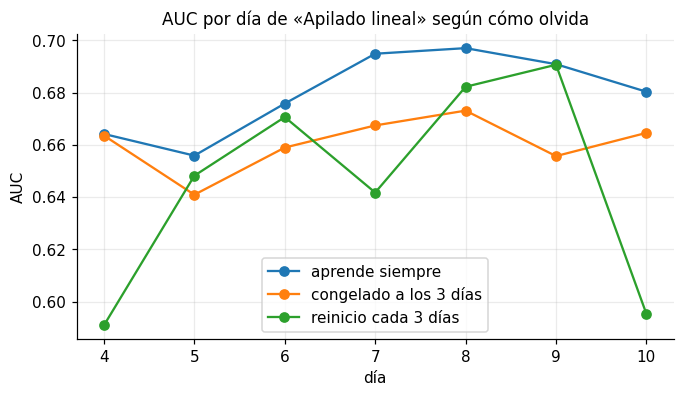

Es una sola ejecución de 7 días: las diferencias pequeñas (< 0.01) no son concluyentes.


,4,5,6,7,8,9,10,media
aprende siempre,0.664,0.656,0.676,0.695,0.697,0.691,0.680,0.680
congelado a los 3 días,0.664,0.641,0.659,0.667,0.673,0.656,0.665,0.661
reinicio cada 3 días,0.591,0.648,0.671,0.642,0.682,0.691,0.595,0.646


In [ ]:
# ------------------------------------------------------------------ 1) ¿Olvidar o seguir aprendiendo?
VARIANTES = {"aprende siempre": RES[GANADOR],
             "congelado a los 3 días": prequential(FABRICAS[GANADOR](), df, congelar_h=24 * 3),
             "reinicio cada 3 días": prequential(FABRICAS[GANADOR](), df, reiniciar_h=24 * 3, fabrica=FABRICAS[GANADOR])}
tic("variantes de olvido")
dias = range(DIAS_AJUSTE + 1, df.dia.max() + 1)
fig, ax = plt.subplots(figsize=(7, 3.6))
tabla = {}
for nom, r in VARIANTES.items():
    aucs = [roc_auc_score(df.revertida[df.dia == d_], r["score"][df.dia == d_]) for d_ in dias]
    tabla[nom] = aucs
    ax.plot(list(dias), aucs, "o-", label=nom)
ax.set(title=f"AUC por día de «{GANADOR}» según cómo olvida", xlabel="día", ylabel="AUC", xticks=list(dias)); ax.legend(); plt.show()
res_olvido = pd.DataFrame(tabla, index=list(dias)).T
res_olvido["media"] = res_olvido.mean(axis=1)
print("Es una sola ejecución de 7 días: las diferencias pequeñas (< 0.01) no son concluyentes.")
res_olvido.round(3)

Seguir aprendiendo gana con claridad. Es la mejor versión todos los días (el día 9 empata con la que se reinicia) y tiene la media más alta, 0,680.

El modelo congelado aguanta, pero se va quedando atrás. El día 4 empata, y a partir de ahí pierde entre 0,015 y 0,035 cada día. Ojo, porque esto no demuestra que haya concept drift. El modelo que sigue aprendiendo también tiene simplemente más datos, y con más datos se aprende mejor aunque nada cambie. Las dos cosas dan la misma gráfica.

Reiniciar es claramente la peor idea. Se ve muy bien en la gráfica: los días 4, 7 y 10, justo después de cada reinicio, el AUC se hunde hasta 0,59–0,64, y luego tarda un par de días en recuperarse. Si hubiera un cambio fuerte, olvidar lo viejo podría compensar, pero aquí no compensa: lo que se pierde al empezar de cero es mucho más que lo que se gana tirando lo antiguo. Es lo que cabía esperar según lo visto en clase: el reentrenamiento completo es para cambios bruscos, y la actualización incremental para cuando los cambios son graduales o no los hay.

Así que no hace falta olvidar nada, basta con seguir aprendiendo. Encaja con lo que vimos en la sección 7: los modelos con ARF, que van sustituyendo árboles cada vez que detectan un cambio, son también los que peor aguantan al final.

In [ ]:
# ------------------------------------------------------------------ 2) Detectores sobre el error del modelo (error binario con umbral fijo)
sc = RES[GANADOR]["score"]; yy = df.revertida.values.astype(int)
umbral = np.quantile(sc[df.h_rel.values < 24 * DIAS_AJUSTE], 0.75)           # marca como "riesgo" el 25 % más alto de los primeros días
error_total = ((sc >= umbral).astype(int) != yy).astype(int)                  # 1 = el modelo se equivocó
ev = df.h_rel.values >= 24 * DIAS_AJUSTE                                      # solo el periodo de evaluación: antes el modelo aún está aprendiendo
error, dia_ev, h_ev = error_total[ev], df.dia.values[ev], df.h_rel.values[ev]


def alarmas(detector, serie):
    out = []
    for i, e in enumerate(serie):
        detector.update(int(e))
        if detector.drift_detected:
            out.append(i)
    return out


DETECTORES = {"ADWIN": lambda: drift.ADWIN(), "DDM": lambda: drift.binary.DDM(), "Page-Hinkley": lambda: drift.PageHinkley(min_instances=30, delta=0.005, threshold=50)}
filas = []
for nom, mk in DETECTORES.items():
    a = alarmas(mk(), error)
    filas.append({"detector": nom, "alarmas": len(a), "primeras (día)": [int(dia_ev[i]) for i in a[:5]]})
print(f"Tasa de error del modelo en el periodo de evaluación (umbral fijo): {error.mean():.1%} · {len(error):,} ediciones")
print("Alarmas sin un cambio conocido: no hay forma de saber si son cambios reales o ruido. Por eso la prueba 3.")
pd.DataFrame(filas).set_index("detector")

Tasa de error del modelo en el periodo de evaluación (umbral fijo): 26.4% · 86,586 ediciones
Alarmas sin un cambio conocido: no hay forma de saber si son cambios reales o ruido. Por eso la prueba 3.


,alarmas,primeras (día)
detector,,
ADWIN,13,"[4, 4, 6, 6, 6]"
DDM,3,"[4, 4, 7]"
Page-Hinkley,23,"[4, 4, 4, 5, 5]"


In [ ]:
# ------------------------------------------------------------------ 3) Cambio inyectado: ¿detectan un empeoramiento real?
rng = np.random.default_rng(1)
mitad = len(error) // 2
error_inj = error.copy()
error_inj[mitad:] = np.maximum(error_inj[mitad:], (rng.random(len(error) - mitad) < 0.15).astype(int))   # de repente falla un 15 % más
filas = []
for nom, mk in DETECTORES.items():
    a = alarmas(mk(), error_inj)
    antes = [i for i in a if i < mitad]; despues = [i for i in a if i >= mitad]
    filas.append({"detector": nom, "falsas alarmas antes": len(antes),
                  "retraso en detectar (ediciones)": (despues[0] - mitad) if despues else None,
                  "retraso (horas)": round(h_ev[despues[0]] - h_ev[mitad], 1) if despues else None})
print(f"Error antes del cambio: {error_inj[:mitad].mean():.1%} · después: {error_inj[mitad:].mean():.1%}")
pd.DataFrame(filas).set_index("detector")

Error antes del cambio: 26.7% · después: 37.0%


,falsas alarmas antes,retraso en detectar (ediciones),retraso (horas)
detector,,,
ADWIN,5,226,0.5
DDM,2,1297,2.5
Page-Hinkley,10,155,0.3


Sobre el error real, los detectores dan 13 alarmas (ADWIN), 3 (DDM) y 23 (Page-Hinkley) en unas 86.600 ediciones. Así, sin más, no sabemos si son cambios de verdad o ruido. No hay ninguna fecha en la que sepamos que algo cambió para poder comprobarlo.

Lo que sí podemos decir es que, si hubo cambios, fueron pequeños. Las primeras alarmas llegan el día 4, justo al empezar la evaluación, y no hay ningún momento en que se acumulen. Además, un cambio con efecto de verdad se tendría que notar en el AUC por día de la primera prueba, y allí el modelo que sigue aprendiendo no tiene ninguna caída brusca.

La prueba del cambio inyectado nos dice al menos que los detectores funcionan. Cuando el error sube de golpe del 27 % al 37 %, los tres lo detectan: ADWIN en media hora, Page-Hinkley en unos 20 minutos y DDM en dos horas y media. Las alarmas "antes del cambio" de esa tabla no son ruido puro, porque esa mitad son los datos reales sin tocar, pero sirven para comparar lo sensible que es cada uno: Page-Hinkley da 10, ADWIN 5 y DDM 2. Page-Hinkley es el más rápido pero también el que más salta. DDM es el más tranquilo y el más lento. ADWIN queda en medio y es el que elegiríamos para vigilar el modelo en un sistema real.

**Conclusión: no hemos encontrado concept drift en estos diez días, y la mejor estrategia es seguir aprendiendo.** Encaja con lo que anticipaba la sección 5, donde tampoco cambiaban los datos.

## 12. Implementación práctica

Hasta aquí hemos contestado a si el modelo funciona. Ahora toca otra pregunta: ¿le sirve de algo a un patrullero de verdad?

Para eso cogemos solo el mejor modelo, el apilado lineal, y lo ponemos en su lugar de dos formas. Primero, una simulación con los días de evaluación, para ver cuánto trabajo le ahorraría. Después, en directo, conectado a la Wikipedia real. En directo no hay etiqueta, así que la evaluación llega más tarde, cuando ya se sabe qué ediciones acabaron revertidas.

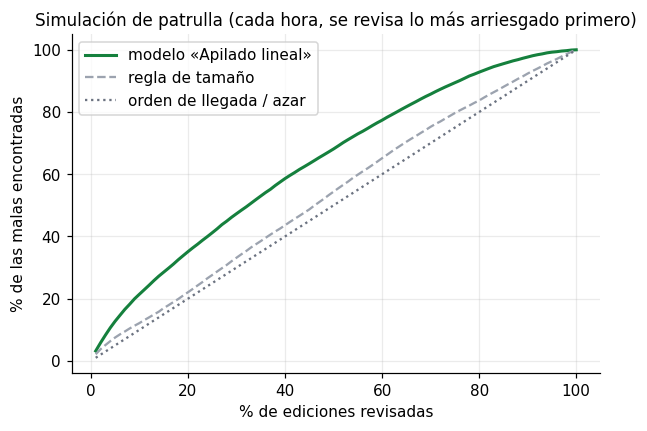

Revisando el 10 % de las ediciones de cada hora, el patrullero encuentra el 21% de las malas (al azar: 10 %) y 53% de lo que revisa es malo (al azar: 25%).
Para encontrar la mitad de las malas debe revisar el 33% de las ediciones; con el orden de llegada, el 50%.


In [ ]:
m = df.h_rel.values >= 24 * DIAS_AJUSTE
y_m, h_m, s_m = df.revertida.values[m], df.h_rel.values[m], RES[GANADOR]["score"][m]
fr = np.linspace(0.01, 1, 100)
g_mod = np.array(curva_ganancia(s_m, y_m, h_m, fr))
g_reg = np.array(curva_ganancia(REF["Regla de tamaño"][m], y_m, h_m, fr))

def a_revisar(g, objetivo):
    return fr[np.argmax(g >= objetivo)]

fig, ax = plt.subplots(figsize=(6.2, 4))
ax.plot(fr * 100, g_mod * 100, color=COL["Apilado"], lw=2, label=f"modelo «{GANADOR}»")
ax.plot(fr * 100, g_reg * 100, "--", color=COL["Regla"], label="regla de tamaño")
ax.plot(fr * 100, fr * 100, ":", color=COL["Azar"], label="orden de llegada / azar")
ax.set(title="Simulación de patrulla (cada hora, se revisa lo más arriesgado primero)", xlabel="% de ediciones revisadas", ylabel="% de las malas encontradas")
ax.legend(loc="upper left"); plt.show()

p10, r10 = patrulla(s_m, y_m, h_m, 0.10)
print(f"Revisando el 10 % de las ediciones de cada hora, el patrullero encuentra el {r10:.0%} de las malas (al azar: 10 %) "
      f"y {p10:.0%} de lo que revisa es malo (al azar: {y_m.mean():.0%}).")
print(f"Para encontrar la mitad de las malas debe revisar el {a_revisar(g_mod, .5):.0%} de las ediciones; con el orden de llegada, el {a_revisar(fr, .5):.0%}.")

Revisando el 10 % de cada hora, el patrullero encuentra el 21 % de las malas, el doble que a ciegas. Y algo más de la mitad de lo que revisa (53 %) acaba siendo revertido, cuando de media es una de cada cuatro.

Dicho en términos de trabajo: para encontrar la mitad de las ediciones malas, con el orden de llegada tendría que revisar la mitad de todo; con el modelo le basta con un tercio (33 %). Es un tercio menos de trabajo para el mismo resultado.

En la gráfica también se ve que la regla del tamaño apenas se separa de la diagonal. Sin el modelo, la intuición de "mirar primero los cambios grandes" no ayuda mucho.

No es un sistema que vaya a encontrar todo el vandalismo. Con el 10 % se le escapa casi el 80 % de lo malo. Pero si el patrullero solo tiene tiempo para una parte, el modelo hace que esa parte rinda bastante más.

In [ ]:
ultimo = df[df.dia == df.dia.max()].copy()
ultimo["riesgo"] = RES[GANADOR]["score"][ultimo.index]
top = ultimo.nlargest(10, "riesgo")[["timestamp", "title", "comment", "riesgo", "revertida"]]
top["riesgo"] = top["riesgo"].round(2)
top["comment"] = top["comment"].str.slice(0, 60)
top

,timestamp,title,comment,riesgo,revertida
118128,2026-10-17 15:27:31+00:00,West Virginia,Undid revision [[Special:Diff/1380400994|13804...,0.95,True
118851,2026-10-17 16:30:58+00:00,Jaani Dushman: Ek Anokhi Kahani,/* Cast */,0.95,False
118886,2026-10-17 16:33:40+00:00,Jaani Dushman: Ek Anokhi Kahani,/* Cast */,0.95,False
118907,2026-10-17 16:36:24+00:00,Jaani Dushman: Ek Anokhi Kahani,/* Cast */,0.94,False
112251,2026-10-17 01:10:15+00:00,Mason Thames,,0.94,True
120229,2026-10-17 19:11:10+00:00,R. Balasaraswathi Devi,/* */,0.94,True
115780,2026-10-17 10:32:37+00:00,Jabba the Hutt,/* */,0.93,False
121614,2026-10-17 21:55:22+00:00,Maggy (Monica and Friends),/* */,0.92,True
120294,2026-10-17 19:20:31+00:00,R. Balasaraswathi Devi,/* Early life */,0.91,True
121475,2026-10-17 21:36:28+00:00,R. Balasaraswathi Devi,/* */,0.91,True


En la cola del último día, 6 de las 10 ediciones con más riesgo acabaron revertidas, frente al 25 % de media.

Las que fallan tienen algo en común: son ediciones seguidas en la misma página. Las tres de *Jaani Dushman*, por ejemplo, son de la sección *Cast* y se hicieron en menos de seis minutos. El modelo ve una página con mucha actividad de golpe y sube el riesgo, que suele ser buena señal, pero no siempre: a veces es solo alguien completando el reparto de una película. Además, que salgan tres de la misma página ocupa tres huecos de la cola con lo que en la práctica es una sola revisión.

Esto da una idea fácil de mejora: agrupar en la cola las ediciones seguidas de la misma página. En cualquier caso, quien decide es el patrullero. El modelo solo le dice por dónde empezar.

### 12.1 Demostración en directo

Aquí el modelo ya está entrenado con todo el histórico. Lo conectamos al flujo en vivo de Wikipedia (**EventStreams**, `recentchange`) y puntúa cada edición anónima que llega, con el mismo extractor de variables que antes.

En directo no hay etiqueta, porque nadie ha tenido tiempo de revertir nada. Lo que se ve es la cola de revisión ordenada por riesgo, que se actualiza cada 15 segundos. La evaluación llega horas después, preguntando a la API qué ediciones acabaron revertidas.

In [ ]:
# ------------------------------------------------------------------ Modelo listo para producción: se pone al día con las etiquetas pendientes
modelo_vivo, ext_vivo = RES[GANADOR]["modelo"], RES[GANADOR]["ext"]
for _, xp, yp, _ in RES[GANADOR]["pendientes"]:
    modelo_vivo.learn_one(xp, yp)

DEMO_SEG = 1800         # duración de la captura en directo (segundos): ~30 min dan unas 250 ediciones; con 2 minutos no hay muestra suficiente
EN_VIVO = True          # False para saltarse la demo
STREAM_URL = "https://stream.wikimedia.org/v2/stream/recentchange"
HEADERS = {"User-Agent": "ProyectoFlujosDatosUC3M/1.0 (proyecto academico; https://github.com/javiacey16/proyecto-series-temporales)"}
RE_IP = re.compile(r"^(\d{1,3}\.){3}\d{1,3}$|^[0-9a-fA-F:]+:[0-9a-fA-F:]+$")


def es_anonima(usuario):
    return usuario.startswith("~") or bool(RE_IP.match(usuario))


def edicion_valida(ev):
    """Misma población que los datos de entrenamiento: wikipedia en inglés, artículos, sin bots, anónimas."""
    return (ev.get("wiki") == "enwiki" and ev.get("type") in ("edit", "new") and ev.get("namespace") == 0
            and not ev.get("bot") and es_anonima(ev.get("user", "")) and "length" in ev)

In [ ]:
import requests
from IPython.display import clear_output, display

filas_vivo = []
if EN_VIVO:
    inicio, ultimo_pintado = time.time(), 0
    try:
        with requests.get(STREAM_URL, headers=HEADERS, stream=True, timeout=(10, 30)) as r:
            for linea in r.iter_lines():
                if time.time() - inicio > DEMO_SEG:
                    break
                if not linea or not linea.startswith(b"data:"):
                    continue
                try:
                    ev = json.loads(linea[5:])
                except ValueError:
                    continue
                if not edicion_valida(ev):
                    continue
                x = ext_vivo(ev["timestamp"], ev["title"], ev.get("comment", ""), ev["length"].get("old") or 0, ev["length"]["new"])
                filas_vivo.append({"revid": ev["revision"]["new"], "hora": dt.datetime.fromtimestamp(ev["timestamp"], dt.timezone.utc).strftime("%H:%M:%S"),
                                   "title": ev["title"], "comment": ev.get("comment", "")[:60],
                                   "riesgo": round(modelo_vivo.predict_proba_one(x).get(True, 0.5), 3), "ts": ev["timestamp"]})
                if time.time() - ultimo_pintado > 15 and filas_vivo:                  # refresca la cola cada 15 s
                    ultimo_pintado = time.time()
                    clear_output(wait=True)
                    print(f"En directo · {len(filas_vivo)} ediciones puntuadas · {len(filas_vivo) / (time.time() - inicio):.2f} ediciones/s")
                    display(pd.DataFrame(filas_vivo).nlargest(10, "riesgo")[["hora", "title", "comment", "riesgo"]])
    except requests.RequestException as e:
        print("No se pudo conectar al flujo en directo:", e)

demo = pd.DataFrame(filas_vivo)
if len(demo):
    demo.to_csv("demo_en_vivo.csv", index=False)
    clear_output(wait=True)
    print(f"Captura terminada: {len(demo)} ediciones puntuadas en {DEMO_SEG // 60} min (guardadas en demo_en_vivo.csv)")
    display(demo.nlargest(10, "riesgo")[["hora", "title", "comment", "riesgo"]])

,hora,title,comment,riesgo
75,18:57:31,Sophia Laforteza,/* */,0.959
57,18:56:04,Sophia Laforteza,,0.946
25,18:52:56,La'uf al HaMillion,,0.911
135,19:02:26,La'uf al HaMillion,,0.905
153,19:04:00,La'uf al HaMillion,,0.903
144,19:03:08,La'uf al HaMillion,,0.902
10,18:52:00,La'uf al HaMillion,,0.900
92,18:59:07,Huddersfield Town A.F.C.,/* First-team squad */ corrected Bronckhort's ...,0.665
31,18:53:14,Type 1 diabetes,,0.635
105,19:00:09,Big Brother (British TV series) series 21,Undid revision [[Special:Diff/1380865374|13808...,0.616


Unas horas después de la captura, la siguiente celda pregunta a la API cuáles de esas ediciones se revirtieron y calcula las mismas métricas que antes. Cuanto más se espere, mejor; lo ideal es un día.

In [ ]:
# ------------------------------------------------------------------ Ejecutar HORAS DESPUÉS de la captura en directo
def etiquetas_api(revids):
    """Consulta la API de Wikipedia: ¿tiene la etiqueta mw-reverted cada revisión?"""
    out = {}
    for i in range(0, len(revids), 50):
        lote = revids[i:i + 50]
        r = requests.get("https://en.wikipedia.org/w/api.php", headers=HEADERS, timeout=60,
                         params={"action": "query", "prop": "revisions", "rvprop": "ids|tags", "revids": "|".join(map(str, lote)),
                                 "format": "json", "formatversion": 2})
        for pag in r.json().get("query", {}).get("pages", []):
            for rev in pag.get("revisions", []):
                out[rev["revid"]] = "mw-reverted" in rev.get("tags", [])
        time.sleep(1)
    return out


if os.path.exists("demo_en_vivo.csv"):
    demo = pd.read_csv("demo_en_vivo.csv")
    etiq = etiquetas_api(demo.revid.tolist())
    demo["revertida"] = demo.revid.map(etiq)
    ok = demo.dropna(subset=["revertida"]).copy(); ok["revertida"] = ok.revertida.astype(bool)
    if len(ok) < 100 or ok.revertida.sum() < 15:
        print(f"Muestra demasiado pequeña ({len(ok)} ediciones, {int(ok.revertida.sum())} revertidas): estas cifras NO son concluyentes, ampliad DEMO_SEG o esperad más horas.")
    if ok.revertida.nunique() == 2:
        n10 = int(np.ceil(.10 * len(ok))); top10 = ok.nlargest(n10, "riesgo")
        print(f"{len(ok)} ediciones con etiqueta · {ok.revertida.mean():.0%} revertidas · AUC en directo: {roc_auc_score(ok.revertida, ok.riesgo):.3f}")
        print(f"Revisando el 10 % con más riesgo: {top10.revertida.mean():.0%} eran malas y se encuentra el {top10.revertida.sum() / ok.revertida.sum():.0%} de todas las malas.")
    else:
        print("Todavía no hay suficientes reversiones para evaluar: volved a ejecutar esta celda más tarde.")
else:
    print("No hay captura en directo guardada (demo_en_vivo.csv).")

180 ediciones con etiqueta · 12% revertidas · AUC en directo: 0.685
Revisando el 10 % con más riesgo: 11% eran malas y se encuentra el 9% de todas las malas.


El resultado en directo hay que leerlo con mucho cuidado, porque la muestra es muy pequeña: 180 ediciones con etiqueta, de las que solo se revirtieron unas 22.

El AUC sale en 0,685, prácticamente el mismo que con los datos históricos (0,682). Es buena señal: el modelo funciona igual con ediciones que no ha visto nunca y que llegan en tiempo real. Aun así, con tan pocas ediciones el margen de error es amplio.

En cambio, el 10 % de arriba no funciona: de las 18 ediciones con más riesgo solo 2 acabaron revertidas, como si las hubiéramos cogido al azar. En la propia cola se ve por qué. Cinco de las diez primeras son de la misma página, *La'uf al HaMillion*, editada varias veces en doce minutos. Es lo mismo que veíamos en la cola del último día, y con una muestra tan pequeña una sola página así se come casi todo el 10 %.

Hay otro detalle: solo se revirtió el 12 % de lo capturado, cuando lo normal es el 25 %. Lo más probable es que no hubiera pasado tiempo suficiente cuando se ejecutó la evaluación, y que algunas de esas ediciones se revirtieran después. Si es así, los números de esta celda están algo por debajo de los reales.

Así que la demo sirve para enseñar que el sistema funciona de punta a punta: se conecta, puntúa en tiempo real y se evalúa después. Pero no para sacar conclusiones sobre su calidad. Para eso hacen falta muchas más ediciones, y las tenemos en la simulación del principio de esta sección.

## 13. Conclusiones

> **Completad esta sección con vuestras palabras tras ejecutar el notebook.** Guía de lo que debe quedar contestado, con los números de las tablas:

1. **El texto aporta**: compara el mismo modelo con y sin texto (logística: «Numérico» frente a «Apilado lineal»; árboles: «ARF numérico» frente a «Apilado ARF») y el texto solo (sección 7). ¿Palabras o caracteres?
2. **Mejor modelo** y cuánto gana frente al azar y frente a la regla simple (recall@10 %, secciones 7 y 12). ¿Qué aporta el historial de la página (ablación)?
3. **¿Árboles o modelo lineal?** En nuestra ejecución **los árboles no ganan**: el ARF numérico llegó a 0,636 de AUC frente a 0,665 de la logística, y el mejor apilado con ARF a 0,658 frente a 0,682 del apilado lineal, con un coste mucho mayor (de 200 a 400 ediciones/s frente a 1.000–10.000, y de 12 a 49 MB). Contad el resultado tal cual y comentad posibles causas (los árboles de Hoeffding necesitan muchos datos para empezar a dividir bien, solo hay diez días, las etiquetas llegan retrasadas y el ARF fue sin ajustar) en lugar de esconderlo: que un modelo sencillo gane también es un resultado.
4. **Retraso de etiqueta**: cuánto empeora el modelo al pasar de 0 a 24 horas (sección 8).
5. **Coste**: ediciones por segundo frente al ritmo real de llegada, y tamaño de los modelos; qué supone usar bigramas y árboles (sección 9).
6. **Agrupamiento**: qué tipos de edición salen y si alguno se revierte claramente más (sección 10).
7. **Concept drift**: si olvidar mejora o empeora frente a seguir aprendiendo, qué dicen los detectores del error y si detectan el cambio inyectado (sección 11).
8. **Data drift**: qué variables cambian y si ese cambio es real o es el ritmo diario; si lo que cambia en los datos afecta al AUC por día (sección 5). En el cambio inyectado, ADWIN lo detectó casi al instante (66 ediciones, 0,1 h) y KSWIN tardó unas 15 horas: con un alpha tan estricto es poco sensible a cambios pequeños de media.
9. **Utilidad práctica**: porcentaje de ediciones que debe revisar el patrullero para encontrar la mitad de las malas, y qué pasó en directo (sección 12).

### Limitaciones
- **Retraso de la etiqueta desconocido**: no tenemos la hora de la reversión; se estudió la sensibilidad (sección 8), pero habría que medirlo. El historial de la página usa ese mismo retraso supuesto.
- **Censura por la derecha**: las ediciones más recientes del CSV tuvieron menos tiempo para ser revertidas, lo que infraestima las positivas del último día.
- **Etiqueta imperfecta**: `mw-reverted` no distingue vandalismo de ediciones revertidas por otros motivos, y una edición mala puede no revertirse nunca.
- **Alcance**: solo Wikipedia en inglés, artículos y ediciones anónimas, durante diez días. Algunos resúmenes de «deshacer» son reversiones de otras ediciones.
- **Evaluación en directo**: muestra pequeña y de pocas horas.
- **Ajuste de hiperparámetros**: cuadrícula pequeña y con tres días de datos; el ARF se usa sin ajustar y con pocos árboles, así que su resultado puede estar infravalorado.
- **Agrupamiento**: sobre variables numéricas; el de texto (`TextClust`) no fue práctico con resúmenes tan cortos.
- **Deriva**: diez días son pocos para ver cambios reales; las conclusiones de las secciones 5 y 11 son orientativas.
- **Historial de páginas**: la memoria del historial crece con el número de páginas distintas; en producción habría que acotarla.

### Mejoras posibles
Historial por usuario (el CSV no incluye el usuario), uso de la hora real de reversión, embeddings de texto (visto en clase: `all-MiniLM-L6-v2` + Hoeffding Tree o Naive Bayes Gaussiano) y ajustar el ARF u otros *ensembles* con ADWIN (`ADWINBagging`, `SRPClassifier`), a costa de más tiempo y memoria. Los árboles online no ganaron al modelo lineal, pero una prueba aparte con árboles **por lotes** reentrenados cada pocas horas sugiere que sí hay relaciones no lineales aprovechables; no está en este cuaderno.

## 14. Uso de herramientas de IA generativa
> Completad con lo que hayáis hecho de verdad. Ejemplo: «Se ha usado Claude (Anthropic) como apoyo para depurar y estructurar el código y para revisar textos redactados por el grupo; las decisiones de diseño, los experimentos y las conclusiones son del grupo.»

## 15. Referencias
- Bifet, A. y Gavaldà, R. (2007). *Learning from time-changing data with adaptive windowing.* SIAM International Conference on Data Mining.
- Domingos, P. y Hulten, G. (2000). *Mining high-speed data streams.* ACM SIGKDD.
- Gama, J., Medas, P., Castillo, G. y Rodrigues, P. (2004). *Learning with drift detection.* SBIA.
- Gama, J., Žliobaitė, I., Bifet, A., Pechenizkiy, M. y Bouchachia, A. (2014). *A survey on concept drift adaptation.* ACM Computing Surveys.
- Gomes, H. M. et al. (2017). *Adaptive random forests for evolving data stream classification.* Machine Learning.
- Hahsler, M. y Bolaños, M. (2016). *Clustering data streams based on shared density between micro-clusters.* IEEE Transactions on Knowledge and Data Engineering.
- Montiel, J. et al. (2021). *River: machine learning for streaming data in Python.* Journal of Machine Learning Research.
- Potthast, M., Stein, B. y Gerling, R. (2008). *Automatic vandalism detection in Wikipedia.* ECIR.
- Wikimedia Foundation: API MediaWiki (`recentchanges`), EventStreams y modelos Revert Risk (Lift Wing).